# Prepaid Card Marketing — Mini-Project 2
## Part 5 of 5: CFPB at-risk groups, policy recommendations and project conclusions (Task D, Steps 11–12)

**Question.** Given potential high fees, and concerns about unsophisticated users, can we identify at-risk groups? What policies can we prescribe to protect them?

**Purpose.** Use the chosen model from Part 3 and the survey's knowledge, hardship and banking measures to define who is at risk, size those groups, test the "unsophisticated user" concern directly, check whether the targeting rule falls unevenly on racial and ethnic groups, and turn the evidence into specific protections. The last section draws conclusions and limitations for the whole project.

| Section | What it delivers |
|---|---|
| 1. Setup | The shared split, the chosen model's scores and the cleaned survey columns |
| 2. Defining "at risk" | The two conditions (likely to use, vulnerable) and why each marker was chosen |
| 3. Size and profile of the at-risk groups | How many people, their usage rate, and who they are |
| 4. The knowledge and confidence gap | How far users' tested knowledge falls short of their self-assessment |
| 5. Fairness audit of the model | Selection, error rates and calibration by race/ethnicity, sex and age; proxy check; what drives the gap; mitigations; intersections |
| 6. Policy recommendations | Each protection tied to the group it protects and the evidence |
| 7. Conclusions and limitations for the whole project | What the project shows, and what it cannot show |

### Summary

- **Yes, at-risk groups can be identified, and they are sizeable.** "At risk" means likely to use a prepaid card (top 20% of model scores, or already a user) **and** vulnerable (at least two of: low financial knowledge, household income under \$30,000, savings under \$1,000, a material hardship, no bank account). That is **996 people, 19.6% of the training set, and they include 62.9% of all prepaid users** (test set: 238 people, 18.7%, 63.4% of users). Their usage rate is 28.3%, 3.22 times the 8.8% average.
- **Risk compounds.** Usage rises from 4.2% among people with none of the five markers to 30.2% among those with all five (test set: 3.7% to 36.7%). **90.3% of the people the targeting rule flags are vulnerable** (92.3% in the test set), so the card company's best prospects and the CFPB's at-risk population are largely the same people.
- **Specific groups to protect** (among people the model flags, training set): the **unbanked**, for whom the card is likely their main account (464 people, usage 24.4%; test 31.0%); people with **low knowledge who are also financially stretched** (643, 23.8%); **low-income households** (600, 22.2%); **low-knowledge users who rate their own knowledge highly** (337, 20.2%); people **also using payday, pawn or check-cashing services** (299, 18.7%); and **SNAP households** (355, 26.8% in training, 20.2% in test).
- **The "unsophisticated user" concern is real, and users underrate it.** On tested knowledge users score 0.51 standard deviations below non-users on average; on self-ratings, only 0.23. They rank themselves 10.7 percentile points higher on self-rated knowledge than their test result places them (non-users: −1.1). Half of low-knowledge users (50.2%) rate their knowledge 5 or more out of 7, the same as low-knowledge non-users (52.8%), so **self-assessment cannot pick them out.**
- **Vulnerable users report worse treatment:** 36.3% felt mistreated by financial services sometimes or often (non-users 17.4%), and 51.3% are not at all familiar with any agency that resolves problems.
- **The targeting rule is not neutral in effect, by race/ethnicity or by sex.** It ranks people about equally well within each racial/ethnic group (ROC-AUC 0.69 to 0.72 for White, Black and Hispanic respondents). However, **37.0% of Black and 36.3% of Hispanic non-users are flagged, against 11.1% of White non-users** (3.3 times as often for both), so they would receive marketing for a product they do not use far more often. This follows real differences in usage and vulnerability: at the same score, Black and Hispanic respondents use prepaid cards *more*. **Women are flagged more than men (22.5% against 17.8%) although usage is identical (8.7% against 8.9%),** and 44.6% of Hispanic women non-users are flagged.
- **The disparity cannot be engineered out of the inputs.** The 17 inputs identify Black or Hispanic respondents (ROC-AUC 0.763) better than they predict prepaid use. Financial knowledge, housing, income and bank access drive most of the gap. This version of the project removes the three predictors that are prohibited bases under ECOA (age, marital status, SNAP). That costs no accuracy, but it hardly changes who is flagged, and the Hispanic gap widens slightly because age had been narrowing it.
- **Policies tied to the evidence:** fee disclosure in plain dollars, tested for comprehension; limits on fees that penalise low balances; a fee-free path to a low-cost bank account; outcome monitoring by race/ethnicity for issuers who use predictive targeting; complaint contacts on the card itself; and help delivered through benefit offices and community organisations. Section 6 separates what the data supports from what is a reasoned suggestion.

All results are associations in a 2016 self-reported survey, unweighted as the brief requires. They describe this sample; they are not causal effects or national estimates.

---
# 1. Setup

This notebook uses the fixed train/test split and 17 predictors from Part 2, and the chosen model's scores from Part 3. Nothing is re-split, re-cleaned or re-modelled.

Three views of the data are used, each for a different job:

- **Training set, out-of-fold scores (5,093 people):** the main file for anything that uses the model score. Each person was scored by a model that never saw them, so profiling is free of leakage.
- **Test set (1,274 people):** used only to confirm that the training patterns hold.
- **Full cleaned sample (6,367 people):** used for descriptions that do not involve the model score, such as the knowledge gap in Section 4. This matches Part 1.

Variables outside the 17 predictors (self-rated knowledge, experiences with financial services, other alternative-finance products) come from `data/cfpb_clean.csv`, joined on `PUF_ID`. Their value labels were taken from the CFPB codebook in `docs/`.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from prep import build_preprocessor, feature_lists, feature_table, load_profile, load_split

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 110, "display.max_rows", 100)

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
SEED = 42
TOP_SHARE = 0.20          # the top-20% rule recommended in Part 3
MIN_MARKERS = 2           # "vulnerable" = at least two of the five markers defined in Section 2

INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9,
})


def fmt(df, formats, hide_index=False):
    """Return a display copy of a table with numbers formatted as text."""
    out = df.copy()
    if isinstance(formats, str):
        formats = {c: formats for c in out.columns if pd.api.types.is_numeric_dtype(out[c])}
    for col, pattern in formats.items():
        if col in out.columns:
            out[col] = out[col].map(lambda v, p=pattern: p.format(v) if pd.notna(v) else "")
    return out.reset_index(drop=True) if hide_index else out


def interval(k, n, z=1.96):
    """95% Wilson interval for a rate of k out of n, as text. Small groups give wide intervals."""
    p, den = k / n, 1 + z ** 2 / n
    centre, half = (p + z ** 2 / (2 * n)) / den, z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return f"{centre - half:.1%} to {centre + half:.1%}"


X_train, X_test, y_train, y_test = load_split()
profile_train, profile_test = load_profile()
train_scores = pd.read_csv(DATA_DIR / "train_oof_scores.csv", index_col="PUF_ID")
test_scores = pd.read_csv(DATA_DIR / "test_scores.csv", index_col="PUF_ID")
clean = pd.read_csv(DATA_DIR / "cfpb_clean.csv", index_col="PUF_ID")

assert train_scores.index.equals(X_train.index) and test_scores.index.equals(X_test.index)
assert clean.index.is_unique and set(clean.index) == set(X_train.index) | set(X_test.index)
assert (clean.loc[y_train.index, "PRODUSE_3"] == y_train).all() and (clean.loc[y_test.index, "PRODUSE_3"] == y_test).all()

threshold = float(np.quantile(train_scores["score_chosen"], 1 - TOP_SHARE))
KNOWLEDGE_CUT = float(X_train["KHscore"].quantile(0.25))   # same cut-off as Part 4, fixed on the training set
RACE = {1: "White, non-Hispanic", 2: "Black, non-Hispanic", 3: "Other, non-Hispanic", 4: "Hispanic"}

MARKERS = {
    "Low financial knowledge": lambda d: d["KHscore"] <= KNOWLEDGE_CUT,
    "Household income under $30,000": lambda d: d["PPINCIMP"] <= 2,
    "Savings under $1,000": lambda d: d["SAVINGSRANGES"] <= 3,
    "At least one material hardship": lambda d: d["HARDSHIP_COUNT"] >= 1,
    "No checking or savings account": lambda d: d["PRODHAVE_1"] == 0,
}


def analysis_frame(ids, scores=None, profile=None):
    """Cleaned survey columns plus the five markers, their count, and (if given) the model score and race/ethnicity."""
    d = clean.loc[ids]
    extra = {"user": d["PRODUSE_3"] == 1}
    extra.update({name: rule(d) for name, rule in MARKERS.items()})   # a missing answer counts as "marker absent"
    extra["markers"] = sum(extra[name].astype(int) for name in MARKERS)
    extra["vulnerable"] = extra["markers"] >= MIN_MARKERS
    if scores is not None:
        extra["score"] = scores["score_chosen"]
        extra["flagged"] = scores["score_chosen"] >= threshold
        extra["at_risk"] = (extra["flagged"] | extra["user"]) & extra["vulnerable"]
    if profile is not None:
        extra["race"] = profile["PPETHM"].map(RACE)
    return pd.concat([d, pd.DataFrame(extra, index=d.index)], axis=1)


train = analysis_frame(X_train.index, train_scores, profile_train)
test = analysis_frame(X_test.index, test_scores, profile_test)
full = analysis_frame(clean.index, profile=clean[["PPETHM"]])

print(f"Training: {len(train):,} respondents, {int(train['user'].sum())} prepaid users ({train['user'].mean():.1%})")
print(f"Test:     {len(test):,} respondents, {int(test['user'].sum())} prepaid users ({test['user'].mean():.1%})")
print(f"Full cleaned sample: {len(full):,} respondents, {int(full['user'].sum())} prepaid users ({full['user'].mean():.1%})")
print(f"Top-{TOP_SHARE:.0%} rule from Part 3: score_chosen >= {threshold:.3f} (cut-off fixed on training scores)")
print(f"Low financial knowledge: KHscore <= {KNOWLEDGE_CUT} (training 25th percentile; covers {(X_train['KHscore'] <= KNOWLEDGE_CUT).mean():.1%} of training respondents)")
print(f"Savings answer missing ('prefer not to say' or 'don't know'): {train['SAVINGSRANGES'].isna().mean():.1%} of training respondents")

Training: 5,093 respondents, 448 prepaid users (8.8%)
Test:     1,274 respondents, 112 prepaid users (8.8%)
Full cleaned sample: 6,367 respondents, 560 prepaid users (8.8%)
Top-20% rule from Part 3: score_chosen >= 0.602 (cut-off fixed on training scores)
Low financial knowledge: KHscore <= -0.57 (training 25th percentile; covers 34.8% of training respondents)
Savings answer missing ('prefer not to say' or 'don't know'): 18.2% of training respondents


---
# 2. Defining "at risk"

**The CFPB uses the score differently from the card company.** The company wants to *find* likely users, so it cares about precision in the top scores. The CFPB wants to *protect* vulnerable ones, and the costs of its mistakes are lopsided: aiming a protection at people who turn out not to be at risk costs little, but missing an at-risk group leaves it unprotected. So the CFPB should favour recall. That is why the definition below counts **actual users** as well as the model's flags: the model alone misses about half of users (Part 3).

**Prepaid use is not harmful in itself.** Many people choose prepaid cards to budget or to avoid overdraft fees. Harm comes from fees combined with a lack of sophistication or financial slack, so "at risk" must combine likely use with vulnerability, not use alone.

The CFPB's concern therefore has two parts, and the definition has two conditions. A person is **at risk** when both hold:

**Condition 1: likely to use a prepaid card.** Either the model places them in the **top 20% of scores** (the targeting rule from Part 3, `score_chosen >= 0.602`), or they **already use** one. The first captures the people a card company would market to; the second captures people already exposed to the fees.

**Condition 2: vulnerable to fees or poor decisions.** At least **two** of the five markers below. Each one is chosen because it makes fees harder to understand, harder to avoid, or harder to absorb:

| Marker | Rule | Why it signals vulnerability |
|---|---|---|
| Low financial knowledge | Knoll–Houts knowledge score in the bottom quarter of the training set (`KHscore <= -0.57`; covers 35% because the score takes only 11 values) | Fee schedules (monthly, reload, ATM, inactivity, decline fees) are hard to compare. This is the brief's "unsophisticated user". Same cut-off as Part 4. |
| Low income | Household income under \$30,000 (`PPINCIMP` 1–2) | The same flat fee takes a much larger share of a small income. |
| Little or no savings | Under \$1,000 in savings (`SAVINGSRANGES` 1–3) | No buffer: a fee or a declined transaction can tip a month into hardship. |
| Material hardship | At least one hardship sometimes or often, such as running out of food or a utility shut-off (`HARDSHIP_COUNT >= 1`) | Shows fees are already competing with essentials. |
| No bank account | No checking or savings account (`PRODHAVE_1 = 0`) | The prepaid card is likely the person's main account, so every deposit, withdrawal and payment can carry a fee. |

**Why two markers rather than one.** Each marker on its own is common (one in three people has low knowledge) and loosely tied to use. The table after next shows that usage rises steeply once markers stack up, and that the model flags very few people with fewer than two. Requiring two keeps the focus on people whose risks compound.

A missing answer is counted as "marker absent". This matters only for savings, where 18% did not give an amount, so the savings marker understates true low savings.

The first table checks each marker on its own: how common it is, and how much more often people with it use prepaid cards.

In [2]:
def marker_table(d):
    rows = []
    for name in MARKERS:
        has = d[name]
        rows.append({"Marker": name, "Share of file": has.mean(), "Usage rate with marker": d.loc[has, "user"].mean(),
                     "Usage rate without": d.loc[~has, "user"].mean(), "Share of users with marker": d.loc[d["user"], name].mean()})
    t = pd.DataFrame(rows).set_index("Marker")
    t["Ratio (with / without)"] = t["Usage rate with marker"] / t["Usage rate without"]
    return t


markers_tr, markers_te = marker_table(train), marker_table(test)
pct = "{:.1%}"
display(fmt(markers_tr.add_suffix(" (train)").join(markers_te[["Usage rate with marker", "Ratio (with / without)"]].add_suffix(" (test)")),
            {**{c: pct for c in ["Share of file (train)", "Usage rate with marker (train)", "Usage rate without (train)", "Share of users with marker (train)",
                                 "Usage rate with marker (test)"]},
             "Ratio (with / without) (train)": "{:.2f}x", "Ratio (with / without) (test)": "{:.2f}x"}))
print(f"Overall usage rate: {train['user'].mean():.1%} (train), {test['user'].mean():.1%} (test).")

,Share of file (train),Usage rate with marker (train),Usage rate without (train),Share of users with marker (train),Ratio (with / without) (train),Usage rate with marker (test),Ratio (with / without) (test)
Marker,,,,,,,
Low financial knowledge,34.8%,14.2%,5.9%,56.2%,2.41x,17.5%,4.17x
"Household income under $30,000",19.2%,17.7%,6.7%,38.6%,2.65x,17.5%,2.58x
"Savings under $1,000",23.8%,16.7%,6.3%,45.1%,2.63x,14.3%,2.00x
At least one material hardship,28.6%,16.2%,5.8%,52.7%,2.78x,15.4%,2.52x
No checking or savings account,14.0%,19.3%,7.1%,30.8%,2.73x,20.8%,3.21x


Overall usage rate: 8.8% (train), 8.8% (test).


**Takeaways**

- **Each marker on its own is associated with about 2.4 to 2.8 times the usage rate** of people without it in training (2.0 to 4.2 times in the test set). Usage rates with a marker range from 14.2% (low knowledge) to 19.3% (no bank account), against 8.8% overall.
- **No bank account has the highest usage rate** (19.3% in training, 20.8% in test) but covers only 30.8% of users. **Low financial knowledge is the most widespread:** it covers 34.8% of everyone and 56.2% of users. Hardship covers 52.7% of users.
- **The test-set ratios move around** (low knowledge 2.41 in training, 4.17 in test). The test set has only 112 users, so the training figures are the steadier guide.
- **Using markers that carry little weight in the model is deliberate.** Part 4 showed savings and hardship add almost nothing to the model's score once bank status, SNAP and credit distress are known. Here they do a different job: they describe how badly fees would hurt someone, not how likely that person is to use a card.

The next table counts how many markers each person has, and shows how usage and the model's targeting change as they stack up.

,People (train),Users (train),Usage_rate (train),Share_flagged (train),People (test),Users (test),Usage_rate (test),Share_flagged (test)
Number of markers (of 5),,,,,,,,
0,2220,94,4.2%,0.6%,535,20,3.7%,0.0%
1,1182,72,6.1%,7.2%,303,21,6.9%,6.3%
2,725,80,11.0%,28.6%,205,17,8.3%,24.9%
3,502,81,16.1%,58.2%,115,21,18.3%,62.6%
4,325,79,24.3%,87.4%,86,22,25.6%,86.0%
5,139,42,30.2%,98.6%,30,11,36.7%,100.0%


Training: 33.2% of people have 2+ markers; usage rate 16.7% with 2+ markers vs 4.9% with 0-1; 90.3% of those the model flags have 2+ markers.
Test: 34.2% of people have 2+ markers; usage rate 16.3% with 2+ markers vs 4.9% with 0-1; 92.3% of those the model flags have 2+ markers.


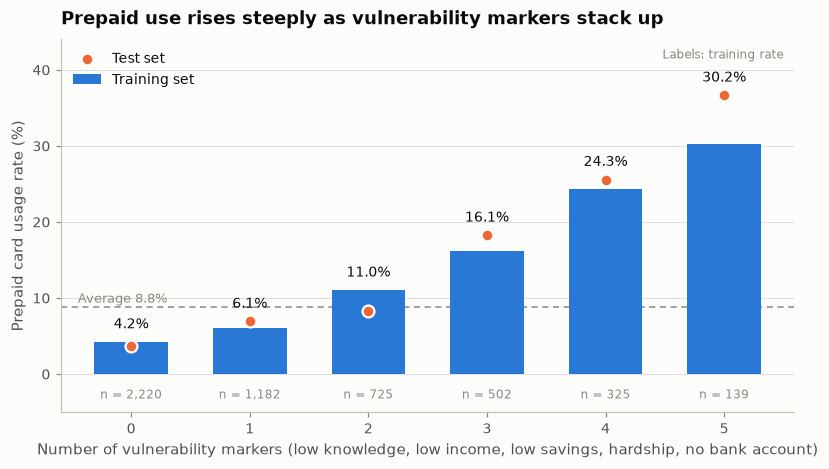

In [3]:
def stacking_table(d):
    t = d.groupby("markers").agg(People=("user", "size"), Users=("user", "sum"), Usage_rate=("user", "mean"), Share_flagged=("flagged", "mean"))
    t.index.name = "Number of markers (of 5)"
    return t


stack_tr, stack_te = stacking_table(train), stacking_table(test)
display(fmt(stack_tr.add_suffix(" (train)").join(stack_te.add_suffix(" (test)")),
            {c: pct for c in ["Usage_rate (train)", "Share_flagged (train)", "Usage_rate (test)", "Share_flagged (test)"]}))

for name, d in [("Training", train), ("Test", test)]:
    v = d["vulnerable"]
    print(f"{name}: {v.mean():.1%} of people have 2+ markers; usage rate {d.loc[v, 'user'].mean():.1%} with 2+ markers vs "
          f"{d.loc[~v, 'user'].mean():.1%} with 0-1; {d.loc[d['flagged'], 'vulnerable'].mean():.1%} of those the model flags have 2+ markers.")

fig, ax = plt.subplots(figsize=(8.6, 4.4))
x = np.arange(len(stack_tr))
ax.bar(x, stack_tr["Usage_rate"] * 100, width=0.62, color=BLUE, zorder=3, label="Training set")
ax.scatter(x, stack_te["Usage_rate"].reindex(stack_tr.index) * 100, s=60, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, zorder=4, label="Test set")
for xi, (rate, n, rate_te) in enumerate(zip(stack_tr["Usage_rate"], stack_tr["People"], stack_te["Usage_rate"].reindex(stack_tr.index))):
    ax.text(xi, max(rate, rate_te) * 100 + 1.8, f"{rate:.1%}", ha="center", fontsize=9, color=INK)
    ax.text(xi, -3.2, f"n = {n:,}", ha="center", fontsize=8, color=MUTED)
base = train["user"].mean() * 100
ax.axhline(base, color=MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=2)
ax.text(-0.45, base + 0.6, f"Average {base:.1f}%", fontsize=8.5, color=MUTED)
ax.set_xticks(x, [str(i) for i in stack_tr.index])
ax.set_ylim(-5, 44)
ax.text(len(stack_tr) - 0.5, 41.5, "Labels: training rate", ha="right", fontsize=8, color=MUTED)
ax.set_xlabel("Number of vulnerability markers (low knowledge, low income, low savings, hardship, no bank account)")
ax.set_ylabel("Prepaid card usage rate (%)")
ax.set_title("Prepaid use rises steeply as vulnerability markers stack up")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
fig.savefig(FIG_DIR / "22_usage_by_vulnerability_markers.png")
plt.show()

**Takeaways**

- **Usage rises with every extra marker:** 4.2% with none, 6.1% with one, 11.0% with two, 16.1% with three, 24.3% with four and 30.2% with all five (training). The test set follows the same path, from 3.7% to 36.7%, with a dip at two markers (8.3%, on 17 users).
- **This is why the threshold is two markers.** One marker leaves usage below the 8.8% average (6.1%) and the model flags only 7.2% of such people. From two markers, usage is above average and the model starts to target people in earnest (28.6% flagged at two, 58.2% at three).
- **33.2% of training respondents have two or more markers.** Their usage rate is 16.7%, against 4.9% for everyone else (test: 34.2%, 16.3% and 4.9%).
- **The model's targets are overwhelmingly vulnerable.** 90.3% of the people the top-20% rule flags in training have two or more markers (92.3% in test). For the CFPB, a company following the Part 4 strategy would be marketing mainly to vulnerable people.

---
# 3. Size and profile of the at-risk groups

### 3.1 The at-risk population

Three overlapping views of the same population:

- **At-risk prospects:** flagged by the model **and** vulnerable. These are the people a card company using the Part 3 rule would market to who are least able to absorb fees.
- **At-risk current users:** already use a prepaid card **and** are vulnerable. They are exposed to fees now, whether or not the model would find them.
- **All at risk:** either of the two.

For each, **lift** is the usage rate divided by the overall 8.8% rate, and **share of all users** is the fraction of every prepaid user in the file who falls in the group.

In [4]:
def population_table(d):
    groups = {"At-risk prospects (flagged and vulnerable)": d["flagged"] & d["vulnerable"],
              "At-risk current users (user and vulnerable)": d["user"] & d["vulnerable"],
              "All at risk (either)": d["at_risk"],
              "For reference: everyone flagged by the model": d["flagged"]}
    base, n_users = d["user"].mean(), d["user"].sum()
    rows = [{"Group": g, "People": int(m.sum()), "Share of file": m.mean(), "Users": int(d.loc[m, "user"].sum()),
             "Usage rate": d.loc[m, "user"].mean(), "95% interval": interval(d.loc[m, "user"].sum(), m.sum()), "Lift": d.loc[m, "user"].mean() / base,
             "Share of all users": d.loc[m, "user"].sum() / n_users} for g, m in groups.items()]
    return pd.DataFrame(rows).set_index("Group")


pop_tr, pop_te = population_table(train), population_table(test)
pop_formats = {"Share of file": pct, "Usage rate": pct, "Lift": "{:.2f}x", "Share of all users": pct}
print("Training set (out-of-fold scores):")
display(fmt(pop_tr, pop_formats))
print("Test set (confirmation):")
display(fmt(pop_te, pop_formats))
print("Usage rate is 100% for 'current users' by definition; it is shown only for completeness.")

flag_users = train["flagged"] & train["user"]
print(f"Training: of the {int(flag_users.sum())} users the model flags, {train.loc[flag_users, 'vulnerable'].mean():.1%} are vulnerable; "
      f"of the {int((train['user'] & ~train['flagged']).sum())} users it misses, {train.loc[train['user'] & ~train['flagged'], 'vulnerable'].mean():.1%} are.")

Training set (out-of-fold scores):


,People,Share of file,Users,Usage rate,95% interval,Lift,Share of all users
Group,,,,,,,
At-risk prospects (flagged and vulnerable),920,18.1%,206,22.4%,19.8% to 25.2%,2.55x,46.0%
At-risk current users (user and vulnerable),282,5.5%,282,100.0%,98.7% to 100.0%,11.37x,62.9%
All at risk (either),996,19.6%,282,28.3%,25.6% to 31.2%,3.22x,62.9%
For reference: everyone flagged by the model,1019,20.0%,218,21.4%,19.0% to 24.0%,2.43x,48.7%


Test set (confirmation):


,People,Share of file,Users,Usage rate,95% interval,Lift,Share of all users
Group,,,,,,,
At-risk prospects (flagged and vulnerable),227,17.8%,60,26.4%,21.1% to 32.5%,3.01x,53.6%
At-risk current users (user and vulnerable),71,5.6%,71,100.0%,94.9% to 100.0%,11.38x,63.4%
All at risk (either),238,18.7%,71,29.8%,24.4% to 35.9%,3.39x,63.4%
For reference: everyone flagged by the model,246,19.3%,60,24.4%,19.4% to 30.1%,2.77x,53.6%


Usage rate is 100% for 'current users' by definition; it is shown only for completeness.
Training: of the 218 users the model flags, 94.5% are vulnerable; of the 230 users it misses, 33.0% are.


**Takeaways**

- **The at-risk population is 996 people (19.6% of the training file) and holds 282 of the 448 prepaid users (62.9%).** Its usage rate is 28.3%, 3.22 times the average. The test set confirms it: 238 people (18.7%), 63.4% of users, 3.39 times.
- **At-risk prospects:** 920 people (18.1%) are both flagged and vulnerable, with a usage rate of 22.4% (2.55 times); test 227 people, 26.4% (3.01 times). About three in four are *not* current users, so they are the people a marketing campaign would newly reach.
- **Nearly two-thirds of current users are vulnerable.** This fits with Part 4's finding that 69.2% of users have a bank account: having an account does not stop someone being low-income, low-knowledge or in hardship.
- **The other 37% of users look like deliberate, mainstream users.** Section 4.1 shows that users with 0–1 markers report mistreatment, difficulty paying bills and use of other high-cost services at rates similar to or below non-users (the exception: 11.1% have reported a problem to an agency, against 6.5% of non-users). They plausibly use prepaid cards by choice, for example to budget. The survey does not ask why people use them, so this is an inference.
- **The model finds the vulnerable users and misses the rest.** 94.5% of the 218 users it flags are vulnerable, against 33.0% of the 230 users it misses. For the CFPB this matters: the people a model-driven campaign would reach are the people least able to absorb fees.

### 3.2 Specific at-risk groups

The at-risk population is broad. The CFPB needs groups that a specific protection can be aimed at. Each group below is a plain rule applied to the people the model flags, so its usage rate shows how strongly it is targeted. The last column shows the share of **all** prepaid users who have the trait, flagged or not. Groups overlap: the same person can be unbanked, low-income and on SNAP, so sizes must not be added.

Two groups use variables outside the model: **other high-cost services** (payday loan, pawn or auto-title loan, or non-bank check cashing; `PRODUSE_1`, `2`, `5`) and **self-rated knowledge** (`SUBKNOWL1`, 1–7). These are profiling columns, not predictors.

In [5]:
OTHER_HIGH_COST = ["PRODUSE_1", "PRODUSE_2", "PRODUSE_5"]


def group_rules(d):
    low_k = d["Low financial knowledge"]
    return {
        "No bank account: card likely their main account": d["No checking or savings account"],
        "Low knowledge and financially stretched (low savings or hardship)": low_k & (d["Savings under $1,000"] | d["At least one material hardship"]),
        "Low knowledge but rates own knowledge 5+ of 7": low_k & (d["SUBKNOWL1"] >= 5),
        "Household income under $30,000": d["Household income under $30,000"],
        "Also uses payday, pawn/title loans or check cashing": (d[OTHER_HIGH_COST] == 1).any(axis=1),
        "Household receives SNAP benefits": d["SNAP"] == 1,
    }


def group_table(d):
    base, n_users = d["user"].mean(), d["user"].sum()
    rows = []
    for g, trait in group_rules(d).items():
        m = d["flagged"] & trait
        rows.append({"Group (among people the model flags)": g, "People": int(m.sum()), "Share of file": m.mean(),
                     "Usage rate": d.loc[m, "user"].mean(), "95% interval": interval(d.loc[m, "user"].sum(), m.sum()),
                     "Lift": d.loc[m, "user"].mean() / base,
                     "Share of all users with this trait": d.loc[d["user"], :].pipe(lambda u: trait[u.index].mean())})
    return pd.DataFrame(rows).set_index("Group (among people the model flags)")


groups_tr, groups_te = group_table(train), group_table(test)
display(fmt(groups_tr.add_suffix(" (train)").join(groups_te[["People", "Usage rate", "Lift"]].add_suffix(" (test)")),
            {"Share of file (train)": pct, "Usage rate (train)": pct, "Lift (train)": "{:.2f}x", "Share of all users with this trait (train)": pct,
             "Usage rate (test)": pct, "Lift (test)": "{:.2f}x"}))

,People (train),Share of file (train),Usage rate (train),95% interval (train),Lift (train),Share of all users with this trait (train),People (test),Usage rate (test),Lift (test)
Group (among people the model flags),,,,,,,,,
No bank account: card likely their main account,464,9.1%,24.4%,20.7% to 28.5%,2.77x,30.8%,126,31.0%,3.52x
Low knowledge and financially stretched (low savings or hardship),643,12.6%,23.8%,20.7% to 27.2%,2.71x,42.9%,158,27.2%,3.10x
Low knowledge but rates own knowledge 5+ of 7,337,6.6%,20.2%,16.2% to 24.8%,2.29x,27.0%,99,24.2%,2.76x
"Household income under $30,000",600,11.8%,22.2%,19.0% to 25.7%,2.52x,38.6%,138,27.5%,3.13x
"Also uses payday, pawn/title loans or check cashing",299,5.9%,18.7%,14.7% to 23.5%,2.13x,18.5%,79,17.7%,2.02x
Household receives SNAP benefits,355,7.0%,26.8%,22.4% to 31.6%,3.04x,25.2%,84,20.2%,2.30x


**Takeaways**

- **Every group is strongly targeted.** Usage rates are 2.1 to 3.0 times the average in training and 2.0 to 3.5 times in the test set. Even the lowest 95% interval (14.7% to 23.5%, other high-cost services) sits well above the 8.8% average, so no group's elevated rate is a fluke of sample size.
- **Unbanked (card likely their main account): 464 flagged people (9.1%), usage 24.4%, 2.77 times; test 126 people, 31.0%, 3.52 times.** This group has the most direct exposure to fees, because deposits, withdrawals and bill payments can each be charged. 30.8% of all users have no bank account.
- **Low knowledge and financially stretched: the largest specific group, 643 people (12.6%), usage 23.8%; test 158, 27.2%.** 42.9% of all users fit this description.
- **Low knowledge but confident: 337 people (6.6%), usage 20.2%; test 99, 24.2%.** 27.0% of all users. They are unlikely to look for help or read fee terms closely (Section 4).
- **Low income: 600 people (11.8%), usage 22.2%; test 138, 27.5%.** 38.6% of all users.
- **Also using payday, pawn/title loans or check cashing: 299 people (5.9%), usage 18.7%; test 79, 17.7%.** 18.5% of all users combine several high-cost products, so their fees add up across products.
- **SNAP households: 355 people (7.0%), 26.8% in training but 20.2% in test** (3.04 against 2.30 times). The group is small in the test set (84 people), so its rate moves between samples, as Part 4 also found.

### 3.3 Who is in the at-risk population?

Share of each group with each characteristic, training set. Race/ethnicity comes from `load_profile()`; everything else from the cleaned survey. Codes follow the CFPB codebook.

In [6]:
def profile_traits(d):
    return {
        "White, non-Hispanic": d["race"] == RACE[1], "Black, non-Hispanic": d["race"] == RACE[2],
        "Hispanic": d["race"] == RACE[4], "Other, non-Hispanic": d["race"] == RACE[3],
        "Age 18-34": d["agecat"] <= 2, "Age 35-61": d["agecat"].between(3, 5), "Age 62 and over": d["agecat"] >= 6,
        "Female": d["PPGENDER"] == 2,
        "No bachelor's degree": d["PPEDUC"] <= 3,
        "Below the federal poverty line": d["fpl"] == 1,
        "Rents": d["HOUSING"] == 2,
        "Sick/disabled or unemployed": d["EMPLOY"].isin([6, 7]),
        "Household receives SNAP": d["SNAP"] == 1,
        "Finds it very difficult to cover monthly bills": d["ENDSMEET"] == 3,
        "Region: Northeast": d["PPREG4"] == 1, "Region: Midwest": d["PPREG4"] == 2,
        "Region: South": d["PPREG4"] == 3, "Region: West": d["PPREG4"] == 4,
        "Lives outside a metropolitan area": d["PPMSACAT"] == 0,
    }


groups ={"All at risk": train["at_risk"], "Not at risk": ~train["at_risk"], "Everyone": pd.Series(True, index=train.index)}
traits = profile_traits(train)
profile = pd.DataFrame({g: {t: v[m].mean() for t, v in traits.items()} for g, m in groups.items()})
profile["Ratio (at risk / not at risk)"] = profile["All at risk"] / profile["Not at risk"]
sizes = pd.DataFrame({g: [int(m.sum())] for g, m in groups.items()}, index=["People"])
display(sizes)
display(fmt(profile, {"All at risk": pct, "Not at risk": pct, "Everyone": pct, "Ratio (at risk / not at risk)": "{:.2f}x"}))

by_race = train.groupby("race").agg(People=("at_risk", "size"), Share_at_risk=("at_risk", "mean")).loc[list(RACE.values())]
by_race_te = test.groupby("race")["at_risk"].mean().rename("Share_at_risk (test)")
print("Share of each race/ethnicity group that is at risk:")
display(fmt(by_race.join(by_race_te), {"Share_at_risk": pct, "Share_at_risk (test)": pct}))

,All at risk,Not at risk,Everyone
People,996,4097,5093


,All at risk,Not at risk,Everyone,Ratio (at risk / not at risk)
"White, non-Hispanic",44.0%,76.8%,70.4%,0.57x
"Black, non-Hispanic",22.4%,7.6%,10.5%,2.93x
Hispanic,28.5%,10.2%,13.8%,2.80x
"Other, non-Hispanic",5.1%,5.3%,5.3%,0.96x
Age 18-34,40.9%,20.0%,24.1%,2.04x
Age 35-61,39.9%,40.5%,40.4%,0.98x
Age 62 and over,19.3%,39.4%,35.5%,0.49x
Female,53.5%,45.7%,47.3%,1.17x
No bachelor's degree,89.3%,55.5%,62.1%,1.61x
Below the federal poverty line,41.0%,3.1%,10.5%,13.43x


Share of each race/ethnicity group that is at risk:


,People,Share_at_risk,Share_at_risk (test)
race,,,
"White, non-Hispanic",3586,12.2%,11.4%
"Black, non-Hispanic",536,41.6%,48.3%
"Other, non-Hispanic",270,18.9%,20.0%
Hispanic,701,40.5%,31.9%


**Takeaways**

- **Race/ethnicity.** 41.6% of Black and 40.5% of Hispanic respondents are at risk, against 12.2% of White respondents (test: 48.3%, 31.9% and 11.4%). Black and Hispanic respondents make up 22.4% and 28.5% of the at-risk population, against 7.6% and 10.2% of everyone else.
- **Younger.** 40.9% are aged 18–34 (20.0% of those not at risk); only 19.3% are 62 or over (39.4%).
- **Deeply economically fragile.** 41.0% are below the federal poverty line (3.1% of those not at risk), 36.2% live in a SNAP household (3.2%), 26.2% find it very difficult to cover monthly bills (2.9%), 24.1% are sick, disabled or unemployed (3.9%) and 61.2% rent (17.4%). Some of this follows from the definition, because low income is one of the markers, but SNAP, employment and housing are not markers.
- **Less formal education:** 89.3% have no bachelor's degree (55.5%). Slightly more are women (53.5% against 45.7%).
- **Geography matters little:** 39.7% live in the South (33.8% of those not at risk), and the share living outside a metropolitan area is the same (13.3% against 13.3%). Region was not a predictor, and the at-risk population is not concentrated in rural areas.
- **What this means for policy:** the at-risk population is reachable through benefit programmes (SNAP), and protections should be designed for people under daily financial strain, not for occasional users choosing between products.

---
# 4. The knowledge and confidence gap

The brief's concern is "unsophisticated users". The survey measures sophistication two ways:

- **Tested:** people answer questions with right and wrong answers. The Knoll–Houts knowledge score (`KHscore`), the three-question Lusardi–Mitchell quiz (`LMscore`, 0–3 correct) and a probability question ("if 1,000 people each buy a ticket with a 1% chance of winning, how many win?", `ON2correct`).
- **Self-rated:** people say how good they are. Overall financial knowledge (`SUBKNOWL1`, 1–7), the financial skill scale (`FSscore`) and skill with percentages (`SUBNUMERACY1`, 1–6).

If users know less but do not *feel* they know less, they are unlikely to seek help or read fee terms closely, and a disclosure regime that relies on them noticing will not protect them.

**Gap in standard deviations** = (users' average − non-users' average) ÷ the spread of the measure across everyone. It puts measures on different scales on a common footing: −0.5 means users sit half a standard deviation lower. This section uses the full cleaned sample (6,367 people), as Part 1 did.

,Type,Non-users (mean),Users (mean),Gap in standard deviations
Measure,,,,
Knowledge test (Knoll-Houts score),Tested,-0.01,-0.49,-0.60
Knowledge quiz (0-3 correct),Tested,2.55,2.17,-0.51
Probability question correct,Tested,0.68,0.48,-0.43
Self-rated financial knowledge (1-7),Self-rated,4.74,4.54,-0.17
Financial skill scale (self-rated),Self-rated,50.96,48.90,-0.16
Self-rated skill with percentages (1-6),Self-rated,4.40,3.89,-0.37


Average gap: tested -0.51 sd, self-rated -0.23 sd. The self-rated gap is 46% of the tested gap.


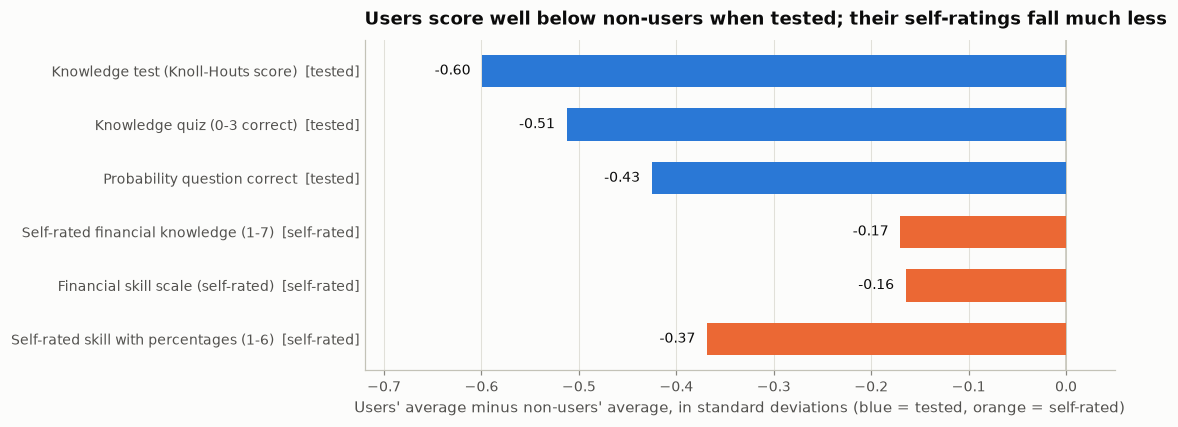

In [7]:
MEASURES = [
    ("KHscore", "Knowledge test (Knoll-Houts score)", "Tested"),
    ("LMscore", "Knowledge quiz (0-3 correct)", "Tested"),
    ("ON2correct", "Probability question correct", "Tested"),
    ("SUBKNOWL1", "Self-rated financial knowledge (1-7)", "Self-rated"),
    ("FSscore", "Financial skill scale (self-rated)", "Self-rated"),
    ("SUBNUMERACY1", "Self-rated skill with percentages (1-6)", "Self-rated"),
]
u = full["user"]
gap = pd.DataFrame([{"Measure": label, "Type": kind, "Non-users (mean)": full.loc[~u, col].mean(), "Users (mean)": full.loc[u, col].mean(),
                     "Gap in standard deviations": (full.loc[u, col].mean() - full.loc[~u, col].mean()) / full[col].std()}
                    for col, label, kind in MEASURES]).set_index("Measure")
display(fmt(gap, {"Non-users (mean)": "{:.2f}", "Users (mean)": "{:.2f}", "Gap in standard deviations": "{:+.2f}"}))
tested_avg = gap.loc[gap["Type"] == "Tested", "Gap in standard deviations"].mean()
self_avg = gap.loc[gap["Type"] == "Self-rated", "Gap in standard deviations"].mean()
print(f"Average gap: tested {tested_avg:+.2f} sd, self-rated {self_avg:+.2f} sd. "
      f"The self-rated gap is {self_avg / tested_avg:.0%} of the tested gap.")

fig, ax = plt.subplots(figsize=(8.8, 3.9))
order = gap.index[::-1]
colors = [BLUE if gap.loc[m, "Type"] == "Tested" else ORANGE for m in order]
ax.barh(np.arange(len(order)), gap.loc[order, "Gap in standard deviations"], height=0.6, color=colors, zorder=3)
for i, m in enumerate(order):
    v = gap.loc[m, "Gap in standard deviations"]
    ax.text(v - 0.012, i, f"{v:+.2f}", va="center", ha="right", fontsize=9, color=INK)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(np.arange(len(order)), [f"{m}  [{gap.loc[m, 'Type'].lower()}]" for m in order])
ax.set_xlim(-0.72, 0.05)
ax.set_xlabel("Users' average minus non-users' average, in standard deviations (blue = tested, orange = self-rated)")
ax.set_title("Users score well below non-users when tested; their self-ratings fall much less")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.savefig(FIG_DIR / "23_knowledge_confidence_gap.png")
plt.show()

The gap can also be measured person by person. Each respondent gets a **percentile** on tested knowledge (`KHscore`) and on self-rated knowledge (`SUBKNOWL1`): where they stand against everyone else, from 0 (lowest) to 100 (highest). **Overconfidence** is the self-rated percentile minus the tested percentile. A positive value means a person ranks themselves higher than their test result ranks them.

In [8]:
kh_pct = full["KHscore"].rank(pct=True) * 100
self_pct = full["SUBKNOWL1"].rank(pct=True) * 100
over = (self_pct - kh_pct).rename("overconfidence")
low_k = full["Low financial knowledge"]
rated_high = full["SUBKNOWL1"] >= 5

conf = pd.DataFrame({
    "Average overconfidence (percentile points)": [over[u].mean(), over[~u].mean()],
    "Share ranking themselves 25+ points above their test": [(over[u] >= 25).mean(), (over[~u] >= 25).mean()],
    "Low knowledge: share rating own knowledge 5+ of 7": [rated_high[u & low_k].mean(), rated_high[~u & low_k].mean()],
    "Low knowledge: average self-rating (1-7)": [full.loc[u & low_k, "SUBKNOWL1"].mean(), full.loc[~u & low_k, "SUBKNOWL1"].mean()],
    "People": [int(u.sum()), int((~u).sum())],
}, index=["Users", "Non-users"]).T
display(fmt(conf.T, {"Average overconfidence (percentile points)": "{:+.1f}", "Share ranking themselves 25+ points above their test": pct,
                     "Low knowledge: share rating own knowledge 5+ of 7": pct, "Low knowledge: average self-rating (1-7)": "{:.2f}", "People": "{:,.0f}"}).T)
print(f"Users with low tested knowledge: {int((u & low_k).sum())} of {int(u.sum())} ({low_k[u].mean():.1%}); "
      f"of these, {int((u & low_k & rated_high).sum())} rate their own knowledge 5 or more out of 7.")

,Users,Non-users
Average overconfidence (percentile points),+10.7,-1.1
Share ranking themselves 25+ points above their test,34.3%,23.8%
Low knowledge: share rating own knowledge 5+ of 7,50.2%,52.8%
Low knowledge: average self-rating (1-7),4.42,4.45
People,560,"5,807"


Users with low tested knowledge: 329 of 560 (58.8%); of these, 165 rate their own knowledge 5 or more out of 7.


**Takeaways**

- **On tested knowledge, users fall well behind:** 0.60 standard deviations below non-users on the knowledge test, 0.51 on the three-question quiz and 0.43 on the probability question (48% answered it correctly, against 68% of non-users).
- **On self-ratings, the gap is much smaller:** 0.17 standard deviations on self-rated knowledge and 0.16 on the financial skill scale. On average the self-rated gap (−0.23) is 46% of the tested gap (−0.51). Users know they are a little behind. They do not see how far.
- **The exception is percentages:** users rate their skill with percentages 0.37 standard deviations lower, so they partly recognise this weakness. Fees stated as percentages (for example, a currency conversion fee of 3%) are therefore hard for this group; dollar amounts are easier to understand.
- **Person by person, users overrate themselves.** They rank 10.7 percentile points higher on self-rated knowledge than their test places them; non-users rank 1.1 points lower. 34.3% of users rank themselves 25 or more points above their test result, against 23.8% of non-users.
- **Self-assessment cannot pick out the unsophisticated user.** 58.8% of users (329 of 560) have low tested knowledge, and 165 of them rate their knowledge 5 or more out of 7. Among low-knowledge people, users rate themselves exactly as highly as non-users (average 4.42 against 4.45; 50.2% against 52.8% rating 5 or more).
- **What this means for policy:** protections that depend on consumers recognising that they need help, such as opt-in education or "read the terms and conditions", will miss about half of the people they are meant for. Defaults and plain disclosures protect people whether or not they see the risk.

### 4.1 Experience with financial services and complaints

The survey also asks about treatment by financial services, familiarity with the agencies that resolve problems (such as the CFPB), and use of other high-cost services. These bear directly on which protections can reach users. Full cleaned sample; "vulnerable users" are users with two or more markers.

In [9]:
EXPERIENCE = {
    "Felt mistreated by financial services sometimes or often": full["CONSPROTECT1"] >= 3,
    "Not at all familiar with agencies that resolve problems": full["CONSPROTECT2"] == 1,
    "Has reported a problem to such an agency": full["CONSPROTECT3"] == 1,
    "Struggles to understand financial information often or always": full["FS2_3"] >= 4,
    "Used payday, pawn/title loan or check cashing": (full[OTHER_HIGH_COST] == 1).any(axis=1),
    "Finds it very difficult to cover monthly bills": full["ENDSMEET"] == 3,
}
groups4 = {"Non-users": ~u, "All users": u, "Vulnerable users (2+ markers)": u & full["vulnerable"], "Other users (0-1 markers)": u & ~full["vulnerable"]}
experience = pd.DataFrame({g: {k: v[m].mean() for k, v in EXPERIENCE.items()} for g, m in groups4.items()})
experience["Ratio (users / non-users)"] = experience["All users"] / experience["Non-users"]
display(pd.DataFrame({g: [int(m.sum())] for g, m in groups4.items()}, index=["People"]))
display(fmt(experience, {**{g: pct for g in groups4}, "Ratio (users / non-users)": "{:.2f}x"}))

seek = {"Government": "INTERCONNECTIONS_9", "Community or faith-based organization": "INTERCONNECTIONS_6", "Financial institution": "INTERCONNECTIONS_7",
        "Professional advisor or counselor": "INTERCONNECTIONS_8", "Friends or co-workers": "INTERCONNECTIONS_5", "Parent": "INTERCONNECTIONS_1"}
advice = pd.DataFrame({g: {k: (full[c] == 1)[m].mean() for k, c in seek.items()} for g, m in list(groups4.items())[:3]})
advice["Ratio (users / non-users)"] = advice["All users"] / advice["Non-users"]
print("Where people seek advice about money (share who name each source):")
display(fmt(advice, {**{g: pct for g in list(groups4)[:3]}, "Ratio (users / non-users)": "{:.2f}x"}))

,Non-users,All users,Vulnerable users (2+ markers),Other users (0-1 markers)
People,5807,560,353,207


,Non-users,All users,Vulnerable users (2+ markers),Other users (0-1 markers),Ratio (users / non-users)
Felt mistreated by financial services sometimes or often,17.4%,29.3%,36.3%,17.4%,1.69x
Not at all familiar with agencies that resolve problems,55.8%,48.4%,51.3%,43.5%,0.87x
Has reported a problem to such an agency,6.5%,12.3%,13.0%,11.1%,1.90x
Struggles to understand financial information often or always,14.6%,19.5%,23.5%,12.6%,1.33x
"Used payday, pawn/title loan or check cashing",9.3%,18.8%,24.6%,8.7%,2.01x
Finds it very difficult to cover monthly bills,6.6%,17.0%,25.8%,1.9%,2.57x


Where people seek advice about money (share who name each source):


,Non-users,All users,Vulnerable users (2+ markers),Ratio (users / non-users)
Government,3.1%,6.8%,8.5%,2.21x
Community or faith-based organization,3.4%,6.8%,6.8%,2.01x
Financial institution,20.5%,18.9%,11.6%,0.93x
Professional advisor or counselor,27.0%,19.1%,9.3%,0.71x
Friends or co-workers,22.7%,25.4%,22.9%,1.11x
Parent,21.2%,26.2%,27.2%,1.24x


**Takeaways**

- **Users report worse treatment.** 29.3% felt mistreated by financial services sometimes or often, against 17.4% of non-users (1.69 times). Among vulnerable users it is 36.3%; among other users it is 17.4%, the same as non-users. The problem sits with the vulnerable users.
- **Users know complaint channels slightly better, and use them.** 48.4% are not at all familiar with agencies that resolve problems (non-users 55.8%), and users are about twice as likely to have reported a problem (12.3% against 6.5%). However, **half of vulnerable users (51.3%) are not at all familiar with any such agency.**
- **Vulnerable users struggle with financial information more:** 23.5% often or always struggle to understand it, against 14.6% of non-users and 12.6% of other users.
- **Fees stack across products.** 24.6% of vulnerable users also used a payday loan, pawn or title loan, or check cashing, against 8.7% of other users and 9.3% of non-users.
- **Day-to-day strain is severe:** 25.8% of vulnerable users find it very difficult to cover monthly bills, against 1.9% of other users.
- **Advice comes from outside the financial system.** Users name government (6.8% against 3.1%) and community or faith organisations (6.8% against 3.4%) about twice as often as non-users. Vulnerable users rarely use professional advisors (9.3%) or financial institutions (11.6%) and most often turn to parents (27.2%) and friends (22.9%). The shares are small, but they show which channels can reach this group: benefit offices and community organisations, not bank branches or advisors.

---
# 5. Fairness audit of the model

**Why this matters.** A model that finds likely prepaid users will tend to concentrate on lower-income, unbanked and minority consumers. If it is used to market a high-fee product, that amounts to steering protected groups toward worse products ("reverse redlining"). Race/ethnicity and sex are not predictors (Part 2), but leaving them out ("fairness through unawareness") is not enough on its own: bank access, income and housing can recreate them. This section measures what the rule actually does.

**Legal and regulatory context** (background for the policy discussion, not legal advice):

- **Equal Credit Opportunity Act (ECOA) / Regulation B** prohibits credit discrimination on race, color, religion, national origin, sex, marital status, age, or receipt of public assistance income. A plain prepaid card is not credit, but cards with overdraft or credit features can be, and regulators apply fair-lending thinking to marketing and targeting. **The project's original 20-predictor model used three of these: age (`agecat`), marital status (`PPMARIT`) and SNAP receipt, which is public assistance.** This version of the project removes them (Part 2), and Section 5.6 measures what that changed.
- **UDAAP** (Dodd-Frank) prohibits unfair, deceptive or abusive acts or practices. Taking unreasonable advantage of consumers' lack of understanding is the core of "abusive", so steering high-fee products at low-knowledge consumers is the risk.
- **Disparate impact:** a neutral-looking rule can still be a problem if its outcomes fall disproportionately on a protected group without a business need that a less discriminatory alternative could meet.
- **CFPB Prepaid Accounts Rule** (effective April 2019): standard short-form fee disclosures, Regulation E error and loss protections, and credit-card rules for overdraft features.

Part 4 (Section 6) showed the rule flags Black and Hispanic respondents about three times as often as White respondents. The audit takes that further:

| Subsection | Test |
|---|---|
| 5.1 | **Selection and error rates by group** (race/ethnicity, sex, age band) |
| 5.2 | **Calibration by group:** do people with similar scores use prepaid cards at similar rates in every group? |
| 5.3 | **Equally vulnerable people:** does the gap remain within the same vulnerability band? |
| 5.4 | **Proxy check:** can the 17 inputs predict race/ethnicity or sex? |
| 5.5 | **What drives the gap:** which predictors push Black and Hispanic respondents' scores up |
| 5.6 | **Mitigations and their cost:** removing the legally sensitive predictors, and the strongest proxies |
| 5.7 | **Intersections:** race/ethnicity by sex and by age |
| 5.8 | **Audit summary:** what was tested, found and changed, and what risk remains |

All audit tests use the training set (out-of-fold scores), with the test set confirming the headline rates. The "Other, non-Hispanic" group is small (270 in training, 65 in test; 23 and 6 users) and its figures are not reliable.

### 5.1 Selection and error rates by group

- **Score percentile:** where a person's score falls among all training scores (0–100).
- **Share flagged (selection rate):** share of the group the top-20% rule would market to. **Selection ratio** = a group's share flagged divided by the most-flagged group's. A common screening flag is a ratio below 0.8 (the "four-fifths rule" from employment law). Here, being selected means receiving an offer for a potentially high-fee product, so a *high* selection rate is the exposure to watch, not a benefit being withheld.
- **True-positive rate:** share of actual users the rule flags. **False-positive rate:** share of *non-users* it flags, meaning people who would receive marketing for a product they do not use. **Precision:** share of those flagged who are users.
- **ROC-AUC within group:** the chance that a randomly chosen user in the group scores above a randomly chosen non-user (0.5 = no better than chance, 1 = perfect).

Race/ethnicity, training set (out-of-fold scores):


Group,"White, non-Hispanic","Black, non-Hispanic","Other, non-Hispanic",Hispanic
People,"3,586",536,270,701
Users,224,98,23,103
Usage rate,6.2%,18.3%,8.5%,14.7%
Median score percentile,42,73,52,74
Share flagged,12.6%,42.2%,20.0%,40.8%
True-positive rate (users flagged),36.2%,65.3%,17.4%,67.0%
False-positive rate (non-users flagged),11.1%,37.0%,20.2%,36.3%
Precision (flagged who are users),17.9%,28.3%,7.4%,24.1%
ROC-AUC within group,0.694,0.719,0.549,0.704
Selection ratio (vs most-flagged group),0.30,1.00,0.47,0.97


Race/ethnicity, test set (confirmation):


Group,"White, non-Hispanic","Black, non-Hispanic","Other, non-Hispanic",Hispanic
People,898,145,65,166
Users,44,29,6,33
Usage rate,4.9%,20.0%,9.2%,19.9%
Median score percentile,44,79,55,63
Share flagged,11.8%,48.3%,24.6%,32.5%
True-positive rate (users flagged),36.4%,72.4%,66.7%,57.6%
False-positive rate (non-users flagged),10.5%,42.2%,20.3%,26.3%
Precision (flagged who are users),15.1%,30.0%,25.0%,35.2%
ROC-AUC within group,0.704,0.670,0.836,0.669
Selection ratio (vs most-flagged group),0.24,1.00,0.51,0.67


Training false-positive rate relative to White respondents: Black 3.3x, Hispanic 3.3x.
Sex, training set:


Group,Male,Female
People,"2,686","2,407"
Users,238,210
Usage rate,8.9%,8.7%
Median score percentile,44,55
Share flagged,17.8%,22.5%
True-positive rate (users flagged),46.2%,51.4%
False-positive rate (non-users flagged),15.0%,19.7%
Precision (flagged who are users),23.0%,20.0%
ROC-AUC within group,0.734,0.722
Selection ratio (vs most-flagged group),0.79,1.00


Age band, training set:


Group,18-34,35-61,62 and over
People,"1,227","2,058","1,808"
Users,151,161,136
Usage rate,12.3%,7.8%,7.5%
Median score percentile,67,45,46
Share flagged,33.5%,19.3%,11.7%
True-positive rate (users flagged),64.2%,51.6%,27.9%
False-positive rate (non-users flagged),29.2%,16.6%,10.3%
Precision (flagged who are users),23.6%,20.9%,18.0%
ROC-AUC within group,0.708,0.760,0.690
Selection ratio (vs most-flagged group),1.00,0.58,0.35


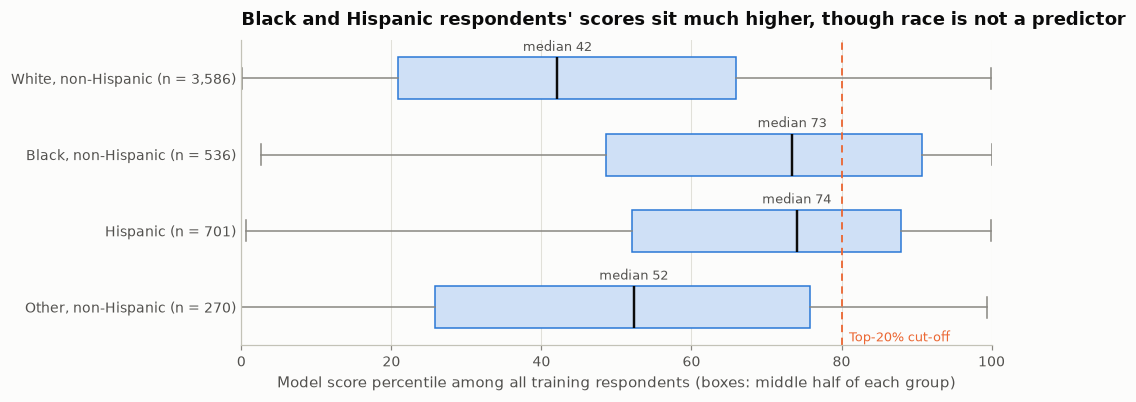

In [10]:
train_sorted = np.sort(train_scores["score_chosen"].to_numpy())
SEX = {1: "Male", 2: "Female"}
AGE_BANDS = ["18-34", "35-61", "62 and over"]


def add_audit_columns(d):
    """Score percentile among training scores, sex, and a three-way age band (from agecat)."""
    return d.assign(score_pct=np.searchsorted(train_sorted, d["score"].to_numpy(), side="right") / len(train_sorted) * 100,
                    sex=d["PPGENDER"].map(SEX),
                    age_band=pd.cut(d["agecat"], [0, 2, 5, 8], labels=AGE_BANDS).astype(str))


train, test = add_audit_columns(train), add_audit_columns(test)


def fairness_table(d, col, order):
    rows = []
    for g in order:
        x = d[d[col] == g]
        rows.append({"Group": g, "People": len(x), "Users": int(x["user"].sum()), "Usage rate": x["user"].mean(),
                     "Median score percentile": x["score_pct"].median(), "Share flagged": x["flagged"].mean(),
                     "True-positive rate (users flagged)": x.loc[x["user"], "flagged"].mean(),
                     "False-positive rate (non-users flagged)": x.loc[~x["user"], "flagged"].mean(),
                     "Precision (flagged who are users)": x.loc[x["flagged"], "user"].mean(),
                     "ROC-AUC within group": roc_auc_score(x["user"], x["score"])})
    t = pd.DataFrame(rows).set_index("Group")
    t["Selection ratio (vs most-flagged group)"] = t["Share flagged"] / t["Share flagged"].max()
    return t


fair_formats = {"People": "{:,}", "Usage rate": pct, "Median score percentile": "{:.0f}", "Share flagged": pct,
                "True-positive rate (users flagged)": pct, "False-positive rate (non-users flagged)": pct,
                "Precision (flagged who are users)": pct, "ROC-AUC within group": "{:.3f}", "Selection ratio (vs most-flagged group)": "{:.2f}"}
fair_tr = fairness_table(train, "race", RACE.values())
fair_te = fairness_table(test, "race", RACE.values())
print("Race/ethnicity, training set (out-of-fold scores):")
display(fmt(fair_tr, fair_formats).T)
print("Race/ethnicity, test set (confirmation):")
display(fmt(fair_te, fair_formats).T)
w, b, h = RACE[1], RACE[2], RACE[4]
print(f"Training false-positive rate relative to White respondents: Black {fair_tr.loc[b, 'False-positive rate (non-users flagged)'] / fair_tr.loc[w, 'False-positive rate (non-users flagged)']:.1f}x, "
      f"Hispanic {fair_tr.loc[h, 'False-positive rate (non-users flagged)'] / fair_tr.loc[w, 'False-positive rate (non-users flagged)']:.1f}x.")
for col, order, title in [("sex", SEX.values(), "Sex"), ("age_band", AGE_BANDS, "Age band")]:
    print(f"{title}, training set:")
    display(fmt(fairness_table(train, col, order), fair_formats).T)

fig, ax = plt.subplots(figsize=(8.8, 3.6))
groups5 = [w, b, h, RACE[3]]
data = [train.loc[train["race"] == g, "score_pct"] for g in groups5][::-1]
bp = ax.boxplot(data, orientation="horizontal", widths=0.55, patch_artist=True, showfliers=False,
                medianprops={"color": INK, "linewidth": 1.6}, whiskerprops={"color": MUTED}, capprops={"color": MUTED})
for patch in bp["boxes"]:
    patch.set(facecolor="#cfe0f6", edgecolor=BLUE)
for i, g in enumerate(groups5[::-1], start=1):
    med = fair_tr.loc[g, "Median score percentile"]
    ax.text(med, i + 0.36, f"median {med:.0f}", ha="center", fontsize=8.5, color=INK2)
ax.axvline(100 * (1 - TOP_SHARE), color=ORANGE, linewidth=1.2, linestyle=(0, (4, 3)))
ax.text(100 * (1 - TOP_SHARE) + 1, 0.55, "Top-20% cut-off", color=ORANGE, fontsize=8.5)
ax.set_yticks(range(1, len(groups5) + 1), [f"{g} (n = {fair_tr.loc[g, 'People']:,})" for g in groups5[::-1]])
ax.set_xlim(0, 100)
ax.set_xlabel("Model score percentile among all training respondents (boxes: middle half of each group)")
ax.set_title("Black and Hispanic respondents' scores sit much higher, though race is not a predictor")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.savefig(FIG_DIR / "24_score_by_race_ethnicity.png")
plt.show()

**Takeaways**

- **Scores sit much higher for Black and Hispanic respondents.** Their median score percentile is 73 and 74, against 42 for White respondents (test: 79, 63 and 44). The rule flags 42.2% and 40.8% against 12.6%.
- **The model ranks people about equally well within each group.** ROC-AUC is 0.719 for Black, 0.704 for Hispanic and 0.694 for White respondents in training (test: 0.670, 0.669 and 0.704). Precision is *higher* for Black and Hispanic respondents (28.3% and 24.1% of those flagged are users, against 17.9%). The model is not less accurate for them.
- **The cost of the model's mistakes falls unevenly.** **37.0% of Black and 36.3% of Hispanic non-users are flagged, against 11.1% of White non-users: 3.3 times as often for both** (test: 42.2% and 26.3% against 10.5%). In a campaign built on this rule, Black and Hispanic consumers who do not use prepaid cards would receive offers for a potentially high-fee product about three times as often as White consumers.
- **The other side:** the rule flags 65.3% of Black and 67.0% of Hispanic users but only 36.2% of White users. White users are mostly the banked, mainstream users the model misses (Part 4).
- **The "Other, non-Hispanic" figures are unreliable** (23 users in training, 6 in test; ROC-AUC 0.549 in training and 0.836 in test).
- **The selection ratio for White respondents is 0.30** (0.24 in test), far below the 0.8 screening line.
- **Sex: women are flagged more often than men (22.5% against 17.8%; selection ratio 0.79, just below 0.8) although usage is the same (8.7% against 8.9%).** 19.7% of women non-users are flagged against 15.0% of men, and precision is lower for women (20.0% against 23.0%). Unlike the racial gap, this one is **not** matched by a difference in use. Sections 5.2, 5.5 and 5.7 look at why.
- **Age: 18–34-year-olds are flagged at 33.5%** (usage 12.3%), against 11.7% of those 62 and over (usage 7.5%; selection ratio 0.35). Age is not a predictor in this version, so this gap comes entirely from the other predictors.
- **Plainly:** leaving race and sex out of the model does not make its effect neutral. A regulator would expect a firm using this rule to monitor these disparities and be able to justify them.

### 5.2 Calibration by group

If the score means the same thing in every group, people in the same score band should use prepaid cards at similar rates whatever their race/ethnicity. Scores are rankings, not probabilities (Part 3), so the check uses actual usage rates within three score bands: the bottom 40%, the middle 40%, and the top 20% that the rule flags. Each cell shows the usage rate and, in brackets, the number of people.

In [11]:
BAND_ORDER = ["Bottom 40% of scores", "Middle 40%", "Top 20% (flagged)"]


def calibration_by_group(d, col, order):
    band = np.select([d["flagged"], d["score_pct"] >= 40], BAND_ORDER[:0:-1], BAND_ORDER[0])
    g = d.assign(band=band).groupby(["band", col])["user"].agg(["mean", "size"])
    return pd.DataFrame({grp: [f"{g.loc[(bd, grp), 'mean']:.1%} ({int(g.loc[(bd, grp), 'size']):,})" if (bd, grp) in g.index else ""
                               for bd in BAND_ORDER] for grp in order}, index=pd.Index(BAND_ORDER, name="Score band"))


print("Usage rate (number of people) by score band, training set:")
display(calibration_by_group(train, "race", list(RACE.values())))
print("Test set (confirmation):")
display(calibration_by_group(test, "race", list(RACE.values())))
print("By sex and age band, training set:")
display(calibration_by_group(train, "sex", list(SEX.values())).join(calibration_by_group(train, "age_band", AGE_BANDS)))

Usage rate (number of people) by score band, training set:


,"White, non-Hispanic","Black, non-Hispanic","Other, non-Hispanic",Hispanic
Score band,,,,
Bottom 40% of scores,"3.0% (1,709)",4.7% (106),7.0% (100),2.5% (122)
Middle 40%,"6.4% (1,424)",14.2% (204),10.3% (116),10.6% (293)
Top 20% (flagged),17.9% (453),28.3% (226),7.4% (54),24.1% (286)


Test set (confirmation):


,"White, non-Hispanic","Black, non-Hispanic","Other, non-Hispanic",Hispanic
Score band,,,,
Bottom 40% of scores,2.8% (396),0.0% (22),0.0% (23),14.9% (47)
Middle 40%,4.3% (396),15.1% (53),7.7% (26),10.8% (65)
Top 20% (flagged),15.1% (106),30.0% (70),25.0% (16),35.2% (54)


By sex and age band, training set:


,Male,Female,18-34,35-61,62 and over
Score band,,,,,
Bottom 40% of scores,"3.3% (1,220)",3.3% (817),5.9% (320),2.4% (961),3.3% (756)
Middle 40%,8.9% (988),"7.1% (1,049)",7.1% (496),7.9% (700),8.7% (841)
Top 20% (flagged),23.0% (478),20.0% (541),23.6% (411),20.9% (397),18.0% (211)


**Takeaways**

- **Race/ethnicity: the score does not overstate Black and Hispanic respondents' likelihood of use; if anything it understates it.** Within the same score band they use prepaid cards more often than White respondents: in the top 20%, 28.3% (Black) and 24.1% (Hispanic) against 17.9% (White); in the middle 40%, 14.2% and 10.6% against 6.4%. The test set agrees for the top band (30.0% and 35.2% against 15.1%). Its smaller cells, such as Hispanic respondents in the bottom band (47 people), are too noisy to read.
- **So the high flag rates in Section 5.1 do not come from inflated scores for these groups.** They come from more Black and Hispanic respondents sitting in the top band, because more of them have the characteristics the model weighs. The bands are wide, so this is a coarse check.
- **Sex: the score does overstate women's likelihood relative to men's.** At the same score band, women use prepaid cards less often than men: 20.0% against 23.0% in the top 20%, and 7.1% against 8.9% in the middle 40%. Together with Section 5.1 (women flagged 22.5% against 17.8%, with equal usage of 8.7% and 8.9%), this is a disparity that **is not explained by a difference in use**.
- **Age:** usage in the top band is 23.6% (18–34), 20.9% (35–61) and 18.0% (62 and over), a mild version of the same pattern for younger adults.
- **The fairness measures cannot all be met at once.** When usage rates differ between groups, a score cannot be equally calibrated, have equal false-positive rates and select groups at equal rates all at the same time. For race/ethnicity the model is roughly calibrated but selects and mis-flags Black and Hispanic non-users far more often. When the use is *marketing a potentially high-fee product*, exposure (selection and false-positive rates) is the measure the CFPB should weigh most. When the use is *finding people who need protection*, calibration matters more.

### 5.3 Equally vulnerable people

Does the gap remain among people who are equally vulnerable, and what do the flagged people in each group look like?

In [12]:
def within_band(d):
    rows = []
    for g in RACE.values():
        x = d[d["race"] == g]
        lo, hi = x[~x["vulnerable"]], x[x["vulnerable"]]
        f = x[x["flagged"]]
        rows.append({"Group": g, "Share vulnerable (2+ markers)": x["vulnerable"].mean(),
                     "Flagged, 0-1 markers": lo["flagged"].mean(), "Flagged, 2+ markers": hi["flagged"].mean(),
                     "Usage rate, 0-1 markers": lo["user"].mean(), "Usage rate, 2+ markers": hi["user"].mean(),
                     "Average markers if 2+": hi["markers"].mean(),
                     "Flagged who are vulnerable": f["vulnerable"].mean(), "Flagged with low knowledge": f["Low financial knowledge"].mean(),
                     "Flagged with no bank account": f["No checking or savings account"].mean()})
    return pd.DataFrame(rows).set_index("Group")


band_tr = within_band(train)
band_formats = {c: pct for c in band_tr.columns if c != "Average markers if 2+"} | {"Average markers if 2+": "{:.2f}"}
print("Training set:")
display(fmt(band_tr, band_formats).T)
band_te = within_band(test)
print("Test set, flag rates within band (confirmation):")
display(fmt(band_te[["Share vulnerable (2+ markers)", "Flagged, 0-1 markers", "Flagged, 2+ markers", "Usage rate, 2+ markers"]], band_formats).T)

Training set:


Group,"White, non-Hispanic","Black, non-Hispanic","Other, non-Hispanic",Hispanic
Share vulnerable (2+ markers),25.3%,52.4%,30.7%,59.6%
"Flagged, 0-1 markers",2.1%,5.9%,4.3%,6.7%
"Flagged, 2+ markers",43.6%,75.1%,55.4%,63.9%
"Usage rate, 0-1 markers",3.9%,9.8%,7.5%,8.1%
"Usage rate, 2+ markers",13.2%,26.0%,10.8%,19.1%
Average markers if 2+,2.75,3.32,2.84,3.06
Flagged who are vulnerable,87.4%,93.4%,85.2%,93.4%
Flagged with low knowledge,64.2%,87.2%,77.8%,83.9%
Flagged with no bank account,41.3%,51.3%,35.2%,49.7%


Test set, flag rates within band (confirmation):


Group,"White, non-Hispanic","Black, non-Hispanic","Other, non-Hispanic",Hispanic
Share vulnerable (2+ markers),26.5%,64.8%,32.3%,50.0%
"Flagged, 0-1 markers",1.7%,5.9%,6.8%,2.4%
"Flagged, 2+ markers",39.9%,71.3%,61.9%,62.7%
"Usage rate, 2+ markers",9.7%,25.5%,19.0%,24.1%


**Takeaways**

- **Vulnerability itself is unevenly spread:** 52.4% of Black and 59.6% of Hispanic respondents have two or more markers, against 25.3% of White respondents.
- **The flag gap remains among equally vulnerable people.** Among people with two or more markers, the rule flags 75.1% of Black and 63.9% of Hispanic respondents, against 43.6% of White respondents (test: 71.3%, 62.7% and 39.9%). Among people with 0–1 markers it flags 5.9% and 6.7% against 2.1%.
- **Within the band, the gap follows real differences.** Vulnerable Black and Hispanic respondents have more markers on average (3.32 and 3.06 against 2.75) and use prepaid cards more (26.0% and 19.1% against 13.2%). Section 5.5 shows which predictors carry the rest of the gap.
- **The people flagged in Black and Hispanic groups are more exposed.** In every group most flagged people are vulnerable (85.2% to 93.4%), but flagged Black and Hispanic respondents more often have low knowledge (87.2% and 83.9% against 64.2%) and no bank account (51.3% and 49.7% against 41.3%).
- **Reading:** for race/ethnicity the disparity is not a modelling error. It mirrors how financial fragility and usage are distributed, so removing race from the inputs cannot remove it (Sections 5.4–5.6 test this).

### 5.4 Proxy check: do the 17 inputs encode race/ethnicity or sex?

If the predictors can recover a protected attribute, excluding the attribute does not keep it out of the model. The test fits a logistic regression that predicts each attribute from the same 17 inputs, with the same preparation, scored by 5-fold cross-validation on the training set. ROC-AUC reads as before: 0.5 means the inputs carry no information about the attribute, and 1 means they reveal it perfectly. For comparison, the same inputs predict prepaid use with ROC-AUC 0.730 (Part 3).

In [13]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
features = feature_table()


def cv_auc(target, columns=None):
    """Cross-validated ROC-AUC of a class-weighted logistic regression predicting `target` from the predictors."""
    columns = list(features.index) if columns is None else columns
    model = Pipeline([("prep", subset_preprocessor(columns)),
                      ("model", LogisticRegression(class_weight="balanced", max_iter=5000, random_state=SEED))])
    oof = cross_val_predict(model, X_train[columns], target, cv=folds, method="predict_proba")[:, 1]
    return roc_auc_score(target, oof)


scaled_cols, binary_cols, nominal_cols = feature_lists()
# The three predictors removed from the model in Part 2, with the preparation they had there (used only in Section 5.6).
ECOA_SENSITIVE = {"agecat": "scaled", "SNAP": "binary", "PPMARIT": "nominal"}
scaled_cols, binary_cols, nominal_cols = (scaled_cols + ["agecat"], binary_cols + ["SNAP"], nominal_cols + ["PPMARIT"])


def subset_preprocessor(columns):
    """The shared preparation rules from prep.py, applied to a subset of the predictors (plus the three removed ECOA-sensitive ones, for Section 5.6)."""
    columns = list(columns)
    return ColumnTransformer([
        ("scaled", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), [c for c in scaled_cols if c in columns]),
        ("binary", SimpleImputer(strategy="most_frequent"), [c for c in binary_cols if c in columns]),
        ("nominal", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), [c for c in nominal_cols if c in columns]),
    ], remainder="drop", verbose_feature_names_out=False)


proxy_targets = {"Black, non-Hispanic (vs everyone else)": train["race"] == RACE[2],
                 "Hispanic (vs everyone else)": train["race"] == RACE[4],
                 "Black or Hispanic (vs everyone else)": train["race"].isin([RACE[2], RACE[4]]),
                 "Female (vs male)": train["sex"] == "Female"}
proxy = pd.DataFrame([{"Attribute predicted from the 17 inputs": k, "Share of respondents": v.mean(), "Cross-validated ROC-AUC": cv_auc(v.astype(int))}
                      for k, v in proxy_targets.items()]).set_index("Attribute predicted from the 17 inputs")
display(fmt(proxy, {"Share of respondents": pct, "Cross-validated ROC-AUC": "{:.3f}"}))

,Share of respondents,Cross-validated ROC-AUC
Attribute predicted from the 17 inputs,,
"Black, non-Hispanic (vs everyone else)",10.5%,0.731
Hispanic (vs everyone else),13.8%,0.757
Black or Hispanic (vs everyone else),24.3%,0.763
Female (vs male),47.3%,0.690


**Takeaways**

- **The 17 inputs identify race/ethnicity better than they predict prepaid use.** They pick out Black or Hispanic respondents with ROC-AUC 0.763 (Black alone 0.731, Hispanic alone 0.757), against 0.730 for prepaid use itself. They identify women with ROC-AUC 0.690.
- **Leaving race/ethnicity and sex out of the model therefore does not keep them out.** The model cannot be described as "unbiased" because protected attributes were excluded. This is why Sections 5.1–5.3 test outcomes directly.

### 5.5 What drives the score gap between groups?

The chosen model is a logistic regression, so each person's score (on the log-odds scale) is a sum of one contribution per predictor: weight × the person's prepared value. Averaging those contributions within each group and subtracting the White average splits the score gap exactly into the part due to each predictor. The model is refitted from its documented settings (as in Part 4) and checked against the Part 3 scores first.

A positive number means the predictor pushes the group's average score **above** White respondents'. The units are log-odds; only their relative size matters here.

Total gap in average log-odds: Black minus White +0.752, Hispanic minus White +0.695


,Black minus White,Hispanic minus White,Black minus White (share of total gap),Hispanic minus White (share of total gap)
Knoll and Houts financial knowledge scale score (KHscore),+0.173,+0.183,23%,26%
Which one of the following best describes your housing situation? (HOUSING),+0.136,+0.147,18%,21%
Household Income (PPINCIMP),+0.105,+0.128,14%,18%
Has: Checking or Savings Account at a bank or credit union (PRODHAVE_1),+0.081,+0.092,11%,13%
Has: Retirement Account (such as a 401k or IRA) (PRODHAVE_4),+0.042,+0.054,6%,8%
Contacted by debt collector in past 12 months (COLLECT),+0.067,+0.028,9%,4%
Number of financial shocks in the past year (0-11) (SHOCKS_COUNT),+0.035,+0.051,5%,7%
Household income volatility (VOLATILITY),+0.027,+0.036,4%,5%
Past 6 months: Paid all your bills on time (MANAGE1_1),+0.036,+0.021,5%,3%
I applied for credit and was turned down (REJECTED_1),+0.032,+0.017,4%,2%


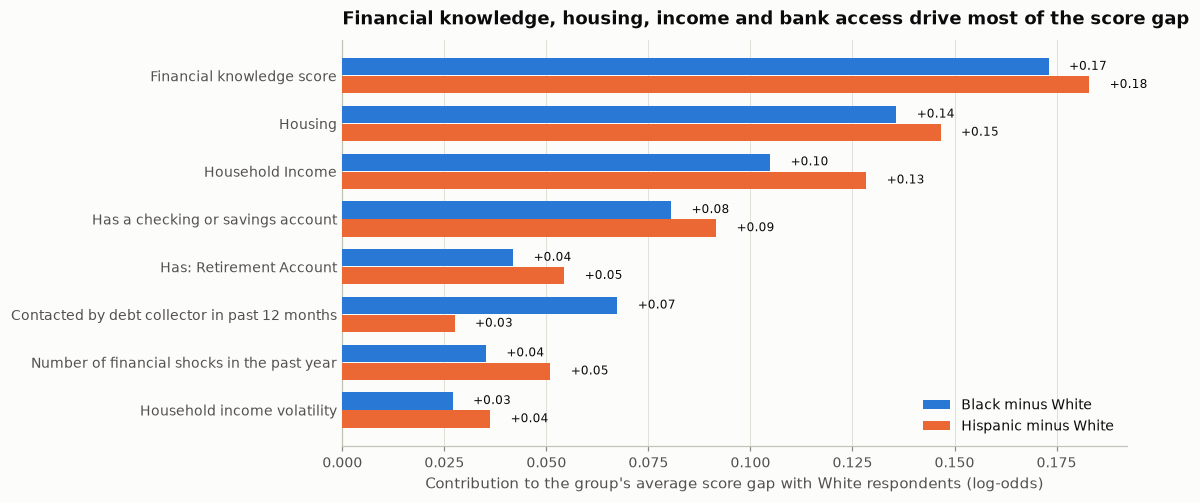

Total gap in average log-odds, Female minus Male: +0.198. Five largest contributors:


,Female minus Male,Share of total gap
Knoll and Houts financial knowledge scale score (KHscore),+0.096,49%
Household Income (PPINCIMP),+0.042,21%
Household income volatility (VOLATILITY),+0.015,7%
Number of financial shocks in the past year (0-11) (SHOCKS_COUNT),+0.014,7%
Has: Retirement Account (such as a 401k or IRA) (PRODHAVE_4),+0.014,7%


In [14]:
def logit():
    """The chosen model's settings from Part 3."""
    return LogisticRegression(C=0.3, class_weight="balanced", max_iter=5000, random_state=SEED)


chosen = Pipeline([("prep", build_preprocessor()), ("model", logit())]).fit(X_train, y_train)
assert np.allclose(chosen.predict_proba(X_test)[:, 1], test_scores["score_chosen"].to_numpy(), atol=1e-8)
prep_step, weights = chosen.named_steps["prep"], chosen.named_steps["model"].coef_[0]
model_cols = prep_step.get_feature_names_out()
contrib = pd.DataFrame(prep_step.transform(X_train) * weights, index=X_train.index, columns=model_cols)
by_predictor = contrib.T.groupby([c if c in features.index else c.rpartition("_")[0] for c in model_cols]).sum().T

white_avg = by_predictor[train["race"] == w].mean()
gaps = pd.DataFrame({"Black minus White": by_predictor[train["race"] == b].mean() - white_avg,
                     "Hispanic minus White": by_predictor[train["race"] == h].mean() - white_avg})
logodds = pd.Series(chosen.decision_function(X_train), index=X_train.index)
for col, grp in [("Black minus White", b), ("Hispanic minus White", h)]:
    assert np.isclose(gaps[col].sum(), logodds[train["race"] == grp].mean() - logodds[train["race"] == w].mean())

gaps["Combined"] = gaps.sum(axis=1)
gaps = gaps.sort_values("Combined", ascending=False)
gaps.index = [f"{features.loc[v, 'label']} ({v})" for v in gaps.index]
total = gaps[["Black minus White", "Hispanic minus White"]].sum()
shares = gaps[["Black minus White", "Hispanic minus White"]] / total
show = gaps[["Black minus White", "Hispanic minus White"]].join(shares.add_suffix(" (share of total gap)"))
print(f"Total gap in average log-odds: Black minus White {total.iloc[0]:+.3f}, Hispanic minus White {total.iloc[1]:+.3f}")
display(fmt(show, {"Black minus White": "{:+.3f}", "Hispanic minus White": "{:+.3f}",
                   "Black minus White (share of total gap)": "{:.0%}", "Hispanic minus White (share of total gap)": "{:.0%}"}))
top2 = [v.rsplit("(", 1)[1].rstrip(")") for v in gaps.index[:2]]

top = gaps.head(8).iloc[::-1]
short = [l.split(" (")[0].replace("Has: Checking or Savings Account at a bank or credit union", "Has a checking or savings account")
          .replace("Which one of the following best describes your housing situation?", "Housing")
          .replace("Knoll and Houts financial knowledge scale score", "Financial knowledge score")
          .replace("Any household member received SNAP benefits", "Household received SNAP")[:52] for l in top.index]
fig, ax = plt.subplots(figsize=(9.2, 4.8))
y = np.arange(len(top))
for off, col, colour in [(0.19, "Black minus White", BLUE), (-0.19, "Hispanic minus White", ORANGE)]:
    ax.barh(y + off, top[col], height=0.36, color=colour, label=col, zorder=3)
    for yi, v in zip(y + off, top[col]):
        ax.text(v + (0.005 if v >= 0 else -0.005), yi, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8, color=INK)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(y, short)
ax.set_xlabel("Contribution to the group's average score gap with White respondents (log-odds)")
ax.set_title("Financial knowledge, housing, income and bank access drive most of the score gap")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.legend(loc="lower right")
fig.savefig(FIG_DIR / "25_score_gap_by_predictor.png")
plt.show()

sex_gap = by_predictor[train["sex"] == "Female"].mean() - by_predictor[train["sex"] == "Male"].mean()
sex_total = sex_gap.sum()
sex_tab = pd.DataFrame({"Female minus Male": sex_gap, "Share of total gap": sex_gap / sex_total}).sort_values("Female minus Male", ascending=False)
sex_tab.index = [f"{features.loc[v, 'label']} ({v})" for v in sex_tab.index]
print(f"Total gap in average log-odds, Female minus Male: {sex_total:+.3f}. Five largest contributors:")
display(fmt(sex_tab.head(5), {"Female minus Male": "{:+.3f}", "Share of total gap": "{:.0%}"}))

**Takeaways**

- **Black respondents' average score is 0.752 log-odds above White respondents'; Hispanic respondents' is 0.695 above.**
- **Four predictors account for most of the gap: financial knowledge, housing, income and bank account.** Together they explain 66% of the Black–White gap (23%, 18%, 14% and 11%) and 78% of the Hispanic–White gap (26%, 21%, 18% and 13%). Debt-collector contact adds 9% for Black respondents.
- **The financial knowledge score is the largest single channel** for both groups. Knowledge-test results also reflect unequal access to education. Because low knowledge *raises* the score, a campaign built on this model leans toward the consumers least able to judge fees. That is the UDAAP concern stated in the introduction.
- **Employment narrows the Hispanic–White gap (−11%).** Age, marital status and SNAP are no longer in the model. In the previous model age had narrowed the Hispanic gap, because Hispanic respondents are younger on average and age had a small positive weight; Section 5.6 shows the effect of removing it.
- **The gap between women and men** (+0.198 log-odds) comes mostly from financial knowledge (49%), then income (21%).

### 5.6 Mitigations and what they cost

This version of the project has already removed the three predictors that are prohibited bases under ECOA (age, marital status and SNAP). The table compares three versions, each scored out-of-fold with the same cross-validation folds as Part 3 (training set only; the test set is not used):

1. **The previous model:** the original 20 predictors including age, marital status and SNAP, with its original setting (`C` = 10).
2. **The current model:** the 17 predictors used throughout this version of the project.
3. **The current model without the two predictors that contribute most to the race/ethnicity score gap** (from Section 5.5).

For each version: overall ranking quality (ROC-AUC, PR-AUC), the top-20% rule's lift and recall, and how the flags fall by group.

In [15]:
X_extended = X_train.join(clean.loc[X_train.index, list(ECOA_SENSITIVE)])


def oof_scores(columns, C=0.3):
    model = Pipeline([("prep", subset_preprocessor(columns)),
                      ("model", LogisticRegression(C=C, class_weight="balanced", max_iter=5000, random_state=SEED))])
    return cross_val_predict(model, X_extended[columns], y_train, cv=folds, method="predict_proba")[:, 1]


current = list(features.index)
assert np.allclose(oof_scores(current), train_scores["score_chosen"].to_numpy(), atol=1e-6), "Refit must reproduce Part 3's out-of-fold scores"
proxies_removed = top2
variants = {f"Previous model: {len(current) + len(ECOA_SENSITIVE)} predictors incl. age, marital status, SNAP": (current + list(ECOA_SENSITIVE), 10),
            f"Current model: {len(current)} predictors (chosen)": (current, 0.3),
            f"Current model without {' and '.join(proxies_removed)} ({len(current) - len(proxies_removed)})":
                ([c for c in current if c not in proxies_removed], 0.3)}

rows = []
for label, (cols, C) in variants.items():
    s = oof_scores(cols, C)
    flag = s >= np.quantile(s, 1 - TOP_SHARE)
    row = {"Version": label, "ROC-AUC": roc_auc_score(y_train, s), "PR-AUC": average_precision_score(y_train, s),
           "Top-20% lift": y_train[flag].mean() / y_train.mean(), "Top-20% recall": flag[y_train.to_numpy() == 1].mean()}
    for g, short_name in [(w, "White"), (b, "Black"), (h, "Hispanic")]:
        in_g = (train["race"] == g).to_numpy()
        row[f"Flagged: {short_name}"] = flag[in_g].mean()
        row[f"Non-users flagged: {short_name}"] = flag[in_g & (y_train.to_numpy() == 0)].mean()
    row["Selection ratio White / Black"] = row["Flagged: White"] / row["Flagged: Black"]
    rows.append(row)
mitigation = pd.DataFrame(rows).set_index("Version")
display(fmt(mitigation, {"ROC-AUC": "{:.3f}", "PR-AUC": "{:.3f}", "Top-20% lift": "{:.2f}x", "Top-20% recall": pct, "Selection ratio White / Black": "{:.2f}",
                         **{c: pct for c in mitigation.columns if c.startswith(("Flagged", "Non-users"))}}).T)
print(f"Predictors removed in the third version: {', '.join(f'{c} ({features.loc[c, 'label']})' for c in proxies_removed)}.")
print("ROC-AUC and PR-AUC here are computed on all 5,093 out-of-fold scores pooled together; Part 3 reports the average across the five folds "
      "(0.730 and 0.225 for the current model); Part 2 puts the fold-to-fold spread of ROC-AUC at about 0.03.")

Version,"Previous model: 20 predictors incl. age, marital status, SNAP",Current model: 17 predictors (chosen),Current model without KHscore and HOUSING (15)
ROC-AUC,0.726,0.728,0.717
PR-AUC,0.215,0.215,0.208
Top-20% lift,2.44x,2.43x,2.45x
Top-20% recall,48.9%,48.7%,49.1%
Flagged: White,12.9%,12.6%,13.5%
Non-users flagged: White,11.3%,11.1%,11.9%
Flagged: Black,43.8%,42.2%,39.7%
Non-users flagged: Black,38.8%,37.0%,34.0%
Flagged: Hispanic,38.5%,40.8%,38.9%
Non-users flagged: Hispanic,33.9%,36.3%,34.6%


Predictors removed in the third version: KHscore (Knoll and Houts financial knowledge scale score), HOUSING (Which one of the following best describes your housing situation?).
ROC-AUC and PR-AUC here are computed on all 5,093 out-of-fold scores pooled together; Part 3 reports the average across the five folds (0.730 and 0.225 for the current model); Part 2 puts the fold-to-fold spread of ROC-AUC at about 0.03.


**Takeaways**

- **Removing age, marital status and SNAP cost nothing measurable.** The previous 20-predictor model scores ROC-AUC 0.726, PR-AUC 0.215 and a top-20% lift of 2.44; the current 17-predictor model scores 0.728, 0.215 and 2.43. Three prohibited bases under ECOA are gone at no cost.
- **But it barely changed who is flagged.** Black respondents are flagged at 42.2% (from 43.8%) and Black non-users at 37.0% (from 38.8%). Hispanic respondents are flagged *more*, at 40.8% (from 38.5%), and Hispanic non-users at 36.3% (from 33.9%), because age had been narrowing their gap. The White/Black selection ratio stays at 0.30.
- **Also removing the two largest gap contributors (financial knowledge and housing) changes little more.** ROC-AUC falls to 0.717, a drop of 0.011, inside the fold-to-fold noise of about 0.03; lift is 2.45 and recall 49.1%. Black non-users flagged fall from 37.0% to 34.0%, Hispanic non-users from 36.3% to 34.6%, and the White/Black selection ratio rises only to 0.34. Income, bank access and the remaining predictors carry the same information.
- **Conclusion:** the disparity cannot be engineered out of the inputs. Any model that finds likely prepaid users will find them disproportionately among Black and Hispanic consumers, because that is where usage and fragility are concentrated. The protection has to come from how the rule is used: identical terms, low fees and outcome monitoring (Section 6).

### 5.7 Intersections

Groups defined by two attributes at once can hide patterns that one attribute alone does not show. The tables cross race/ethnicity (the three larger groups) with sex and with age band. Cells with fewer than 20 users are marked: their usage and flag rates are too noisy to support a conclusion.

In [16]:
def intersections(d, col, order):
    rows = []
    for r in [w, b, h]:
        for g in order:
            x = d[(d["race"] == r) & (d[col] == g)]
            rows.append({"Race/ethnicity": r, col.replace("_", " ").capitalize(): g, "People": len(x), "Users": int(x["user"].sum()),
                         "Usage rate": x["user"].mean(), "Share flagged": x["flagged"].mean(),
                         "Non-users flagged": x.loc[~x["user"], "flagged"].mean(),
                         "Readable?": "Yes" if x["user"].sum() >= 20 else "Too few users"})
    return pd.DataFrame(rows)


inter_formats = {"Usage rate": pct, "Share flagged": pct, "Non-users flagged": pct}
print("Race/ethnicity by sex, training set:")
display(fmt(intersections(train, "sex", list(SEX.values())), inter_formats, hide_index=True))
print("Race/ethnicity by age band, training set:")
display(fmt(intersections(train, "age_band", AGE_BANDS), inter_formats, hide_index=True))

Race/ethnicity by sex, training set:


,Race/ethnicity,Sex,People,Users,Usage rate,Share flagged,Non-users flagged,Readable?
0,"White, non-Hispanic",Male,1907,115,6.0%,11.2%,9.9%,Yes
1,"White, non-Hispanic",Female,1679,109,6.5%,14.3%,12.4%,Yes
2,"Black, non-Hispanic",Male,244,39,16.0%,38.9%,34.1%,Yes
3,"Black, non-Hispanic",Female,292,59,20.2%,44.9%,39.5%,Yes
4,Hispanic,Male,382,69,18.1%,35.9%,28.8%,Yes
5,Hispanic,Female,319,34,10.7%,46.7%,44.6%,Yes


Race/ethnicity by age band, training set:


,Race/ethnicity,Age band,People,Users,Usage rate,Share flagged,Non-users flagged,Readable?
0,"White, non-Hispanic",18-34,780,72,9.2%,25.1%,21.8%,Yes
1,"White, non-Hispanic",35-61,1369,66,4.8%,11.2%,9.7%,Yes
2,"White, non-Hispanic",62 and over,1437,86,6.0%,7.2%,6.7%,Yes
3,"Black, non-Hispanic",18-34,129,39,30.2%,57.4%,51.1%,Yes
4,"Black, non-Hispanic",35-61,247,41,16.6%,38.9%,34.5%,Yes
5,"Black, non-Hispanic",62 and over,160,18,11.2%,35.0%,31.7%,Too few users
6,Hispanic,18-34,244,28,11.5%,51.2%,46.3%,Yes
7,Hispanic,35-61,334,51,15.3%,36.5%,32.2%,Yes
8,Hispanic,62 and over,123,24,19.5%,31.7%,26.3%,Yes


**Takeaways**

- **Women are flagged more than men within every racial/ethnic group:** 14.3% against 11.2% (White), 44.9% against 38.9% (Black) and 46.7% against 35.9% (Hispanic).
- **Hispanic women are the clearest case of over-flagging.** Their usage rate (10.7%) is well below Hispanic men's (18.1%), yet they are flagged more often, and **44.6% of Hispanic women who do not use prepaid cards are flagged**. The model's knowledge and income channels (Section 5.5) push their scores up without matching use.
- **Young Black adults have the highest rates of both use and exposure:** usage 30.2%, flagged 57.4%, and **51.1% of non-users flagged**. Half of young Black adults who do not use prepaid cards would receive offers.
- **Young Hispanic adults are also over-flagged relative to use:** usage 11.5%, flagged 51.2% (46.3% of non-users). Older Hispanic adults (62 and over) use more (19.5%) and are flagged less (31.7%).
- **Black respondents aged 62 and over (18 users) are too few to read.** Every other cell has at least 20 users, but most are still small: treat these rates as indications, not precise estimates.

### 5.8 Audit summary

**What we tested.** Selection rates, error rates, within-group ranking quality and calibration by race/ethnicity, sex and age band. Flag rates among equally vulnerable people. Whether the inputs encode race/ethnicity and sex. Which predictors drive the score gaps. Two input-level mitigations and their cost. Race/ethnicity crossed with sex and with age.

**What we found.**
- The top-20% rule flags Black and Hispanic respondents 3.3 times as often as White respondents among **non-users** (selection ratio for White respondents: 0.30). Within the same score band Black and Hispanic respondents use prepaid cards *more* often, so the disparity reflects where usage and fragility are concentrated, not scores inflated for these groups.
- **Women are flagged more often than men (22.5% against 17.8%; selection ratio 0.79, just below the 0.8 screening flag) although they use prepaid cards at the same rate.** This disparity is not explained by usage, and is sharpest for Hispanic women.
- The 17 inputs identify Black or Hispanic respondents (ROC-AUC 0.763) better than they predict prepaid use (0.730). Financial knowledge, housing, income and bank access drive most of the gap.
- The previous model used three predictors (age, marital status, SNAP) that are prohibited bases under ECOA.

**What we changed.** Age, marital status and SNAP were removed from the model (Part 2) at no cost in accuracy, so the targeting model no longer uses any prohibited basis under ECOA. Removing the strongest proxies as well costs little accuracy but leaves most of the disparity in place, so it is not recommended as a fix on its own.

**What risk remains.** Used to market a high-fee product, this rule would put offers disproportionately in front of Black and Hispanic consumers, women and young adults, including many who do not use prepaid cards and who have low financial knowledge. That is the reverse-redlining and UDAAP risk described above. It can be managed through product terms and monitoring (Section 6), not through the model alone. The model must not be described as unbiased.

---
# 6. Policy recommendations

Each recommendation names the group it protects and the evidence from this notebook. The **Basis** column separates what the data supports from what is a reasoned suggestion. The survey records whether someone used a prepaid card, not which fees they paid, so no recommendation about fee *levels* can be tested here. Those rest on the evidence about who the users are.

| # | Policy | Group it protects | Evidence in this notebook | Basis |
|---|---|---|---|---|
| 1 | **Short, standard fee disclosure before purchase, in dollars, with a typical monthly cost for common usage patterns**, tested with low-knowledge consumers before adoption. This would build on the CFPB's existing short-form prepaid disclosure. | Low-knowledge users, especially the confident ones (337 flagged, usage 20.2%; 27.0% of all users) | Tested knowledge gap −0.51 sd against −0.23 self-rated. 50.2% of low-knowledge users rate their knowledge 5+ of 7. Only 48% of users answer the probability question correctly (68% of non-users), and users rate their percentage skills 0.37 sd lower (Section 4). | **Data** on who is at risk and why. Dollars rather than percentages is a **reasoned suggestion**. |
| 2 | **Limit fees that penalise low balances and frequent small transactions:** cap or ban negative-balance, declined-transaction and inactivity fees; no overdraft or credit features on cards marketed to at-risk segments; and at least one free way to load cash and one free way to withdraw it. | Low-income and low-savings users; people in hardship (600 flagged low-income people, usage 22.2%; 38.6% of users) | 72.6% of flagged people report a hardship and 61.0% have under \$1,000 saved (Part 4). 25.8% of vulnerable users find it very difficult to cover monthly bills (Section 4.1). 41.0% of the at-risk population is below the poverty line (Section 3.3). | **Reasoned suggestion.** The survey does not record fees paid, so it shows who fees would hurt most, not which fees are charged or how much. **Trade-off:** caps set too low could push providers out, leaving the unbanked with costlier options such as check cashers, so levels should be set with fee and cost data. |
| 3 | **A fee-free route to a low-cost bank account** (for example, accounts certified under the Bank On standard), offered at sign-up and at conversion, with no penalty for leaving the card. | The unbanked, for whom the card is the main account (464 flagged, usage 24.4%, test 31.0%) | Not having a bank account carries the model's largest weight (odds ratio 0.58, Part 4). 45.5% of flagged people (Part 4) and 51.3% of flagged Black and 49.7% of flagged Hispanic respondents have no account (Section 5). | **Data** on the association; that an offer would move people into accounts is a **reasoned suggestion** to pilot. |
| 4 | **Fair-marketing supervision for issuers that use predictive targeting:** identical prices and terms for everyone offered the card; no age, marital status or public-assistance inputs in targeting models; and regular reporting of offers, take-up, fees and complaints by race/ethnicity, sex and age. Treat targeting low-knowledge consumers with high-fee products as a UDAAP review trigger. | Black and Hispanic consumers, women, young adults | 37.0% of Black and 36.3% of Hispanic non-users are flagged, against 11.1% of White non-users. Women are flagged 22.5% against 17.8% with equal usage, and 44.6% of Hispanic women non-users are flagged. The inputs identify Black or Hispanic respondents with ROC-AUC 0.763. Removing the ECOA-sensitive inputs cost no accuracy. Knowledge is the largest channel of the gap (Section 5). | **Data** on the disparities and on the cost of removing the inputs. The supervisory design is a **reasoned suggestion**. |
| 5 | **Put the complaint route on the product:** the CFPB complaint contact printed on the card, in the app and on statements, in plain language. | Vulnerable users | 36.3% of vulnerable users felt mistreated sometimes or often (17.4% of non-users), and 51.3% are not at all familiar with any agency that resolves problems. Users who do know the channels use them (12.3% have reported a problem, against 6.5% of non-users) (Section 4.1). | **Data** on the need. The remedy is a **reasoned suggestion**. |
| 6 | **Help delivered where users already go, by default rather than opt-in:** fee guidance through SNAP and benefit offices, community and faith organisations, and at the point of sale. | Low-knowledge users and SNAP households (355 flagged, usage 26.8% in training, 20.2% in test) | Users seek advice from government (6.8% against 3.1%) and community organisations (6.8% against 3.4%) about twice as often as non-users; vulnerable users rarely use advisors (9.3%) or banks (11.6%). Overconfidence means opt-in courses will miss many (Section 4). | **Reasoned suggestion.** This survey cannot test whether education changes behaviour, and evidence elsewhere is mixed, so it should complement policies 1–3, not replace them. |
| 7 | **Supervise prepaid cards alongside other high-cost services** (payday, pawn/title loans, check cashing), looking at total fees per customer rather than one product at a time. | Users combining several high-cost products (299 flagged, usage 18.7%; 18.5% of users) | 24.6% of vulnerable users also used one of these services, against 8.7% of other users and 9.3% of non-users (Section 4.1). | **Data** on the overlap. Joint supervision is a **reasoned suggestion**. |
| 8 | **Benefit and payroll cards: free access to the full amount and a free choice of how to be paid**, with limits on fees for any card a person is required to use. | SNAP households and people who are sick, disabled or unemployed (24.1% of the at-risk population, against 3.9% of others) | SNAP households are 36.2% of the at-risk population against 3.2% of others (Section 3.3), and use prepaid cards at 23.0% in training (Part 4). | **Reasoned suggestion.** The survey does not say whether anyone's card was a benefit or payroll card, so the link is plausible, not shown. |

**What is new and what builds on existing rules.** The 2019 Prepaid Accounts Rule already requires a short-form fee disclosure, Regulation E error and loss protections, and credit-card rules for overdraft features. Policies 1 and 2 *extend* it: a dollar-based typical monthly cost, comprehension testing, and limits on low-balance fees. Policies 3 to 8 are additions.

**Priorities.** Policies 1, 3 and 4 rest most directly on this notebook's evidence. Policy 2 targets the group the data shows is most exposed, but it needs fee data to set any caps. Policies 6 and 8 are the least supported on their own.

**What the data does and does not support.** The data identifies *who* is exposed and *why* fees would hurt them more: users are concentrated among people with low knowledge, low income, little savings and no bank account, they underrate their knowledge gap, and they report more mistreatment. It does not measure fees paid, whether disclosure or education changes behaviour, or whether fee caps would reduce supply. Those effects should be checked with the CFPB's own complaint and supervisory data, or piloted and evaluated before being adopted at scale.

---
# 7. Conclusions and limitations for the whole project

### What the project shows

1. **Prepaid card use is a minority behaviour concentrated among financially fragile households, but most users are mainstream** (Part 1). 8.8% of the 6,367 respondents used a reloadable prepaid card. Use is higher with low income, little savings, hardship, no bank account and low financial knowledge, yet 69.2% of users have a bank account.
2. **Prediction is possible, but only moderately accurate** (Parts 2–3). Seventeen predictors covering resources, strain, knowledge, banking and demographics feed a class-weighted logistic regression; age, marital status, sex and SNAP receipt are excluded as prohibited bases under fair-lending law. It was chosen over a random forest and XGBoost, which performed about as well, because it is easier to explain. On the test set it reaches ROC-AUC 0.746 and PR-AUC 0.247 (random guessing would score 0.5 and 0.088). The top 20% of scores contains about half of all users at 2.4 to 2.8 times the average rate.
3. **For the card company, targeting works as a ranking tool, even on observable data** (Part 4). Bank-account status, housing, income and credit distress keep a lift of about 2.0 to 2.4. There are two markets: the fragile users the model finds, and banked, mainstream users it misses.
4. **For the CFPB, the at-risk groups are identifiable and large** (Part 5). About one respondent in five is both likely to use a card and vulnerable, and that group holds 62.9% of all users. Vulnerability compounds: usage rises from 4.2% with no markers to 30.2% with all five. Users underrate their knowledge gap, report more mistreatment, and often combine several high-cost products.
5. **The commercial opportunity and the consumer-protection risk are the same people.** 90.3% of the people the targeting rule flags are vulnerable. The rule reaches Black and Hispanic non-users about three times as often as White non-users, and women more often than men with no difference in use. Leaving protected attributes out does not prevent this: the inputs encode race/ethnicity, and removing the strongest proxies hardly changes the result. A responsible strategy and sound regulation point the same way: transparent dollar-based fees, low-balance protections, a route into low-cost bank accounts, no ECOA-sensitive targeting inputs (as this version already does), and monitoring of outcomes by group.

### Limitations

- **Self-reported 2016 survey.** Answers may be misremembered or shaded. The prepaid market has changed since 2016, including new federal prepaid rules that took effect in 2019 and the growth of low-cost digital accounts, so current users may differ.
- **The outcome records use, not fees paid or frequency.** The survey does not say how often a card was used, which fees were paid, or whether the person was harmed. "At risk" here means exposed to potential harm, not shown to be harmed. No fee level or cap can be tested with this data.
- **Unweighted results are not national estimates.** As the brief requires, survey weights were ignored, so every figure describes this sample, not the US adult population.
- **Associations, not causes.** No characteristic in this project has been shown to cause prepaid card use or harm. Policy effects, such as whether a disclosure or an account offer changes behaviour, would need a pilot or experiment.
- **Model performance is moderate.** Three in four people flagged are not users, and about half of users are missed. The test set holds only 112 users, so test figures carry wide uncertainty (Part 3 puts the test ROC-AUC between 0.699 and 0.794).
- **Judgement calls in Part 5.** The five markers, their cut-offs and the two-marker threshold are reasoned choices, not fixed standards; another reasonable definition would give somewhat different sizes. The savings marker understates low savings, because 18.2% of respondents did not give an amount. The knowledge measures test general financial knowledge, not understanding of prepaid fees specifically.
- **Target is past use, a proxy for future demand.** The model is trained on who *has used* a prepaid card, which stands in for who *would* take one up. The survey covers the general adult population, not card applicants, so the project models the market, not an approval funnel.
- **Fairness measures conflict.** Because usage differs between groups, no score can be equally calibrated, have equal error rates and select groups equally at once. The audit reports all three and argues for which one matters in each use; another reasonable weighting could reach a different verdict.
- **Small groups are unstable.** The "Other, non-Hispanic" group (23 users in training) and segment rates in the test set (for example, SNAP households) move noticeably between samples. Race/ethnicity is available only in four broad categories.

### Suggested next steps

- Combine these profiles with data that records fees paid and harm, such as CFPB complaint data or issuer transaction data, to test where fees actually fall.
- Test disclosure formats with low-knowledge consumers before mandating one.
- If the targeting rule is used, pilot it with outcome monitoring by group from the start.

### Hand-off for final integration

Shared numbers used in this notebook (base rate, sample sizes, top-20% cut-off, Part 4 figures) match the earlier notebooks. The table below records this notebook's key outputs.

In [17]:
handoff = pd.DataFrame({
    "Value": [f"{len(train):,} / {len(test):,}", f"{train['user'].mean():.1%} / {test['user'].mean():.1%}",
              f"score_chosen >= {threshold:.3f}", f"{MIN_MARKERS}+ of 5 markers; low knowledge = KHscore <= {KNOWLEDGE_CUT}",
              f"{int(pop_tr.loc['All at risk (either)', 'People']):,} ({pop_tr.loc['All at risk (either)', 'Share of file']:.1%})",
              f"{int(pop_te.loc['All at risk (either)', 'People']):,} ({pop_te.loc['All at risk (either)', 'Share of file']:.1%})",
              f"{pop_tr.loc['All at risk (either)', 'Share of all users']:.1%} / {pop_te.loc['All at risk (either)', 'Share of all users']:.1%}",
              "22_usage_by_vulnerability_markers.png, 23_knowledge_confidence_gap.png, 24_score_by_race_ethnicity.png, 25_score_gap_by_predictor.png"]},
    index=["Training / test respondents", "Usage rate (train / test)", "Targeting rule (from Part 3)", "Vulnerable",
           "At risk, training set", "At risk, test set", "Share of users who are at risk (train / test)", "Figures saved"])
display(handoff)

,Value
Training / test respondents,"5,093 / 1,274"
Usage rate (train / test),8.8% / 8.8%
Targeting rule (from Part 3),score_chosen >= 0.602
Vulnerable,2+ of 5 markers; low knowledge = KHscore <= -0.57
"At risk, training set",996 (19.6%)
"At risk, test set",238 (18.7%)
Share of users who are at risk (train / test),62.9% / 63.4%
Figures saved,"22_usage_by_vulnerability_markers.png, 23_knowledge_confidence_gap.png, 24_score_by_race_ethnicity.png, 25..."
